# Joint vs R2D2M2 vs stated scales on real designs, refitted by lme4

## 1. Motivation

The [simulated datasets](simulated.ipynb) compared three ways to set the prior scales of a Bayesian generalized linear mixed model (GLMM).<br>
Only the joint prior kept the marginal R² and the links' saturation flat as the design grew.<br>
But that comparison read every measure off the ground truth, on simulated covariates.<br>
So it could not say whether a prior's levels match those of real grouped tables.

This experiment draws y on the designs of real tables instead.<br>
lme4 refits each drawn y, as it fitted the real one.<br>
If a prior could have produced the real tables, each real fit falls at a random rank among its refits.

**Contents**
1. Motivation
2. Design
3. Measures
4. Reading
5. Records
6. Ranks
7. Outside, containment and distance
8. Singular fits and the slope over d
9. Saturation
10. The joint prior split by its draws
11. Candidate defaults by reweighting
12. Candidate defaults as their own priors
13. Finding

References

## 2. Design

Each real table lends its design to every prior, and lme4 (Bates et al., 2015) fits both sides alike.
- **Registry:** real grouped tables from public sources, each with the mixed model its documentation fits, collected and fitted by lme4 in MixedBench 1.0.13.
- **Fits:** each documented model with estimates and an intercept, on the rows it was fitted on (section 5 counts the rest).
- **Design:** the design matrix X and each grouping factor's random-effect columns Z_k, as lme4 builds them from the documented formula, with its offset.
- **Columns:** X's columns other than 0/1 z-scored, which the refit's intercept and slopes absorb.
- **Draws:** each a prior, its parameters and a y in the family the registry fitted (Gaussian, Bernoulli or Poisson).
- **Refits:** per fit and prior, draws until 39 refits have estimates, at most 78, since the registry holds only fits with estimates.
- **Random effects:** correlated as the formula fits them, under a Lewandowski-Kurowicka-Joe (LKJ) prior for `(x | g)` and independent for `(x || g)`.
- **Refit:** the documented formula with the drawn y as its response, so each refit is the registry's fit with y swapped.
- **Priors:** the five of [simulated.ipynb's section 4](simulated.ipynb), `joint`, `r2d2m2-0.5`, `r2d2m2-1`, `survey` and `unit`.
- **`joint-phi`:** the joint prior with φ ~ Beta(2, 3), on the 761 fits whose joint refits took a median of at most 120 s (section 12).
- **`joint-phi-tau0`:** `joint-phi` with τ₀ ~ LogUniform(0.1, 3), on the same fits.
- **`joint-phi-tau0-logit` and `joint-phi-tau0-log`:** `joint-phi-tau0` with τ ~ LogUniform(0.5, 3) and LogUniform(0.1, 3), each on the fast fits of its own link.
- **Random streams:** shared by every prior, so that the five differ only in their scales, `joint-phi` from the joint prior only in φ and the draws after it, `joint-phi-tau0` from `joint-phi` only in τ₀, and the per-link priors from `joint-phi-tau0` only in τ.
- **Recorded draws:** what the prior drew, beside each refit and its ground truth.

`registry.py` builds the designs and draws and refits y, one cluster task per fit, and writes `registry.csv.gz`, which this notebook reads.

## 3. Measures

Each measure is read off a fit's estimates, the refit's or the registry's, by the variance partition of [simulated.ipynb's section 3](simulated.ipynb) (Nakagawa et al., 2017).
- **$R^2_m$, $R^2_c$ and the fixed share $R^2_m / R^2_c$:** one per fit.
- **Intraclass correlation (ICC):** one per grouping factor, every factor in one distribution, each paired with the same factor of the registry's fit.
- **sd(η):** the standard deviation of the fitted linear predictor over the rows, on the logit and log links only, since a Gaussian η is on y's raw scale.
- **Singular share:** the share of fits that lme4 flags as singular, with some variance estimated at 0 or some correlation at ±1.
- **Saturated share:** the share of fits with some |η̂| above 10, on the logit and log links only.
- **y's mean:** over the fit's rows, the real y's and each drawn y's, on the logit and log links only, read off the data rather than a fit.

A fit without slopes (d = 1) has $R^2_m$ = 0 and a fixed share of 0 on both sides.<br>
So it leaves those two measures, whose ties would otherwise pull its ranks toward uniform.

## 4. Reading

### Ranks

A registry fit's rank among the m refits under one prior runs from 0, below every refit, to m, above every refit.<br>
If real tables were draws from the prior, the rank would be uniform.<br>
Then 2 / (m + 1) of the fits would fall outside the refits' range, 2/40 = 5 % at m = 39.<br>
Over 132 fits, as on the logit link's fast fits, that share has an sd of 1.9 points, and 8 or more fall outside with probability 0.34.<br>
Ties, as at the ICC of 0 of a singular fit, break at random in the histograms.<br>
The share outside takes the chance of a rank of 0 or m over that random draw, so that it does not depend on the draw.<br>
The histograms hold 10 bins of 4 ranks each.<br>
A fit whose 78 draws left fewer refits spreads its rank r into the 10 bins by (r + V) / (m + 1), with V uniform on [0, 1).

The ranks' histogram reads by its shape:
- **∩:** the prior is wider than real tables, as a prior meant to cover every table intends.
- **U:** the prior misses real tables on both sides.
- **Falling:** the refits lie above the registry, so the prior's levels are too high.
- **Rising:** the refits lie below the registry, so the prior's levels are too low.

### Containment and distance

Two more numbers compare the registry's fits with all refits under one prior, as two samples.
- **Containment:** the share of one sample inside the other's 1st to 99th percentile band, both ways.
- **Wide prior:** keeps the registry inside its refits' band, but not every refit inside the registry's.
- **Distance:** the Wasserstein-1 distance between the two samples' pooled ranks, from 0 to 1, without a test.

A classifier two-sample test is left out, since it rewards matching where a prior is meant to be wider.

### The joint prior's losses

The joint prior loses a measure of one family to another prior when three things hold.
- **Joint misses:** the joint prior leaves more registry fits outside its refits' range than uniform ranks would.
- **Fewer outside:** the other prior leaves fewer registry fits outside its refits' range, with the paired difference's 95 % interval below 0.
- **No larger distance:** its Wasserstein-1 distance is at most the joint prior's.

Below the uniform share, the joint prior is already wider than real tables, as a prior meant to cover every table intends.<br>
Another prior that leaves still fewer fits outside is only wider there.

The paired difference compares the same fits under both priors.<br>
Its interval takes the normal approximation, clustered by fit, since a fit's factors share its design.

### The slope over d

The slope of $R^2_m$ over the design matrix's rank d says how fast the explained variance climbs with d.<br>
Each fit's $R^2_m$ in the registry, or its mean over the refits under one prior, is regressed on log₂ d.<br>
The regression is ordinary least squares (OLS) over the fits with d ≥ 2, with a 95 % interval by the normal approximation.

## 5. Records

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from candidates import OVERRIDES
from mixedbench import registry
from scipy import special, stats

from tabdgp import Beta, Glmm, LogUniform, Uniform, fidelity

SEED = 2026  # the ties' and the bins' random draws
ESTIMATED = ['ok', 'singular', 'warning']  # the statuses of a fit with estimates
FAMILIES = ['gaussian', 'bernoulli', 'poisson']
ARMS = [
    'joint',
    'joint-phi',
    'joint-phi-tau0',
    'joint-phi-tau0-logit',
    'joint-phi-tau0-log',
    'r2d2m2-0.5',
    'r2d2m2-1',
    'survey',
    'unit',
]
ARM = 'joint-phi'  # the joint prior with φ ~ Beta(2, 3), run only on the fast fits
ARM_TAU0 = 'joint-phi-tau0'  # joint-phi with τ₀ up to 3, on the same fits
# joint-phi-tau0 with τ per link, each on the fast fits of its link
LINK_ARMS = {'bernoulli': 'joint-phi-tau0-logit', 'poisson': 'joint-phi-tau0-log'}
REFITS = 39  # refits with estimates per fit and prior
BINS = 10  # the rank histograms' bins, 4 of the 40 ranks each

fits = pd.read_csv('registry-fits.csv')  # a row per registry model, its task or why it was dropped
tasks = fits[fits['task'].notna()].astype({'task': int, 'rank': int, 'factors': int})
records = pd.read_csv('registry.csv.gz')  # a row per fit, draw and prior
records = records.merge(tasks[['task', 'family', 'rank']], on='task')
print(f'{len(tasks)} of {len(fits)} registry models, {len(records)} refits')

778 of 931 registry models, 225837 refits


In [2]:
# the registry's models that have no task, by why they were dropped
dropped = fits[fits['task'].isna()]
print(pd.crosstab(dropped['reason'], dropped['family'])[FAMILIES].to_string())

family        gaussian  bernoulli  poisson
reason                                    
no estimates       120         13       11
no intercept         6          2        1


A refit without estimates ended in an error or a timeout.<br>
Most errors come from a y that lme4 cannot fit: a constant y, or a ground truth that saturates the link.<br>
So the errors count against their prior, as the share of its draws without estimates until 39 have them.<br>
Its ranks are taken over the refits that remain.

In [3]:
# the share of refits without estimates, per family and prior
statuses = pd.crosstab(
    [records['family'], records['arm']], records['fit_status'], normalize='index'
)
print(statuses['error'].unstack('family')[FAMILIES].round(3).to_string())
print(f'timeouts: {int((records["fit_status"] == "timeout").sum())}')

# the fits whose 78 draws left a prior fewer than 39 refits with estimates
estimated = records['fit_status'].isin(ESTIMATED).groupby([records['arm'], records['task']]).sum()
print(estimated[estimated < REFITS].to_string())

family                gaussian  bernoulli  poisson
arm                                               
joint                    0.000      0.064    0.082
joint-phi                0.000      0.064    0.086
joint-phi-tau0           0.000      0.011    0.045
joint-phi-tau0-log         NaN        NaN    0.034
joint-phi-tau0-logit       NaN      0.011      NaN
r2d2m2-0.5               0.000      0.049    0.086
r2d2m2-1                 0.000      0.047    0.086
survey                   0.005      0.046    0.332
unit                     0.000      0.054    0.116
timeouts: 9
arm        task
joint      144     38
joint-phi  144     38
survey     317     37
           335     34
           506     33
           542     36
           560     22
           695     37
           707     18
           729     22
           761     28
           762     24
unit       707     27


`joint-phi` and `joint-phi-tau0` ran only on the fits whose joint refits took a median of at most 120 s.<br>
The slower fits took most of the joint prior's refit time, and each fit's joint records set the rule before `joint-phi` ran on it.<br>
The per-link priors ran only on the fast fits of their own link.


In [4]:
# the fast fits, by their joint refits' median time, and the slow ones' share of the joint prior's time
joint_seconds = records[records['arm'] == 'joint'].groupby('task')['fit_seconds']
median_seconds = joint_seconds.median()
fast = median_seconds[median_seconds <= 120].index
slow = median_seconds[median_seconds > 120]
slow_share = joint_seconds.sum()[slow.index].sum() / joint_seconds.sum().sum()
print(
    f"skipped: {slow.round().astype(int).to_dict()} s, {slow_share:.1%} of the joint prior's time"
)
for arm in [ARM, ARM_TAU0]:
    ran = records[records['arm'] == arm]['task'].unique()
    print(f'{arm} ran on {len(ran)} fits, exactly the fast ones: {set(ran) == set(fast)}')
for family, arm in LINK_ARMS.items():
    ran = records[records['arm'] == arm]['task'].unique()
    on_link = tasks[tasks['task'].isin(fast) & (tasks['family'] == family)]['task']
    print(
        f'{arm} ran on {len(ran)} fits, exactly the fast {family} ones: {set(ran) == set(on_link)}'
    )

skipped: {384: 125, 391: 366, 393: 401, 409: 546, 450: 860, 477: 268, 527: 146, 542: 228, 543: 1225, 582: 174, 590: 873, 609: 133, 610: 391, 622: 152, 695: 154, 761: 305, 762: 258} s, 77.4% of the joint prior's time
joint-phi ran on 761 fits, exactly the fast ones: True
joint-phi-tau0 ran on 761 fits, exactly the fast ones: True
joint-phi-tau0-logit ran on 132 fits, exactly the fast bernoulli ones: True
joint-phi-tau0-log ran on 93 fits, exactly the fast poisson ones: True


In [5]:
MEASURES = {
    'r2_marginal': '$R^2_m$',
    'r2_conditional': '$R^2_c$',
    'fixed_share': '$R^2_m / R^2_c$',
    'icc': 'ICC',
    'sd_eta': 'sd(η)',
    'y_mean': "y's mean",
}
PER_FIT = ['r2_marginal', 'r2_conditional', 'fixed_share', 'sd_eta', 'y_mean']  # one value per fit


def selectMeasures(table: pd.DataFrame) -> pd.DataFrame:
    # sd(η) and y's mean only on the logit and log links, R²_m and the fixed share only on fits with slopes
    table = table.merge(tasks[['task', 'family', 'rank']], on='task')
    raw_scale = (table['family'] == 'gaussian') & table['measure'].isin(['sd_eta', 'y_mean'])
    no_slopes = (table['rank'] == 1) & table['measure'].isin(['r2_marginal', 'fixed_share'])
    return table[~raw_scale & ~no_slopes]


def readFits() -> pd.DataFrame:
    # fits.csv holds a row per grouping factor, the fit's own measures repeated on each
    reference = pd.read_csv(registry.path('fits.csv'), keep_default_na=False, na_values=[''])
    reference['id'] = (
        reference['source'] + '/' + reference['object'] + '/' + reference['model_index'].astype(str)
    )
    # y's mean, which the registry lacks, from the real table at the fit's rows
    return reference.merge(tasks[['id', 'task', 'y_mean']], on='id')


def readRegistry(reference: pd.DataFrame) -> pd.DataFrame:
    # the fit's own measures, the fixed share at the records' 4 decimals
    per_fit = reference.drop_duplicates('task').copy()
    explained = per_fit['sigma2_fixed'] + per_fit['sigma2_random']
    per_fit['fixed_share'] = (per_fit['sigma2_fixed'] / explained).round(4)
    measures = per_fit.melt(id_vars='task', value_vars=PER_FIT, var_name='measure')
    measures['k'] = 0

    # each factor's ICC, k in lme4's order, which is the order of a fit's rows and its refits' columns
    factors = reference[['task', 'icc']].rename(columns={'icc': 'value'})
    factors['k'] = factors.groupby('task').cumcount() + 1
    factors['measure'] = 'icc'
    return selectMeasures(pd.concat([measures, factors]).dropna(subset=['value']))


def readRefits() -> pd.DataFrame:
    # each refit's measures beside its ground truth's, y's mean the drawn y's on both sides
    fitted = records[records['fit_status'].isin(ESTIMATED)]
    fitted = fitted.assign(fit_y_mean=fitted['y_mean'], truth_y_mean=fitted['y_mean'])
    parts = []
    for measure in PER_FIT:
        part = fitted[['task', 'draw', 'arm']].assign(
            measure=measure, k=0, value=fitted[f'fit_{measure}'], truth=fitted[f'truth_{measure}']
        )
        parts.append(part)
    for k in range(1, tasks['factors'].max() + 1):
        part = fitted[['task', 'draw', 'arm']].assign(
            measure='icc', k=k, value=fitted[f'fit_icc_{k}'], truth=fitted[f'truth_icc_{k}']
        )
        parts.append(part)
    return selectMeasures(pd.concat(parts).dropna(subset=['value']))


fits_table = readFits()  # fits.csv's rows of the kept fits, a row per fit and factor
real = readRegistry(fits_table)  # a row per fit, measure and factor (k = 0 for a fit's own measure)
refits = readRefits()  # a row per refit, measure and factor

### Check: ground truth against refit

A refit is only informative if it recovers its ground truth's measures.<br>
A Bernoulli y recovers them least, since one binary draw per row carries little information.

In [6]:
# Spearman's correlation between each ground truth's measure and its refit's
correlations = {}
# (y's mean is read off the drawn y, so no refit stands between it and its truth)
estimates = refits[refits['measure'] != 'y_mean']
for (family, measure, arm), table in estimates.groupby(['family', 'measure', 'arm']):
    correlations[(family, MEASURES[measure], arm)] = table['truth'].corr(
        table['value'], method='spearman'
    )
print(pd.Series(correlations).unstack().round(2).to_string())

                           joint  joint-phi  joint-phi-tau0  joint-phi-tau0-log  joint-phi-tau0-logit  r2d2m2-0.5  r2d2m2-1  survey  unit
bernoulli $R^2_c$           0.79       0.78            0.84                 NaN                  0.82        0.79      0.79    0.83  0.77
          $R^2_m / R^2_c$   0.71       0.72            0.75                 NaN                  0.80        0.83      0.83    0.87  0.82
          $R^2_m$           0.79       0.78            0.82                 NaN                  0.83        0.86      0.86    0.89  0.84
          ICC               0.74       0.77            0.80                 NaN                  0.83        0.81      0.81    0.86  0.82
          sd(η)             0.79       0.79            0.84                 NaN                  0.83        0.78      0.78    0.81  0.78
gaussian  $R^2_c$           0.98       0.98            0.98                 NaN                   NaN        0.98      0.98    0.99  0.99
          $R^2_m / R^2_c$   0.87  

## 6. Ranks

Each row of a figure is one measure.<br>
Its first panel shows the measure's distribution in the registry and under each prior, as empirical cumulative distribution functions (CDFs).<br>
The other panels show the registry's ranks under each prior, with the uniform share of 1/10 dashed.

In [7]:
def pairRegistry() -> pd.DataFrame:
    # each refit beside the registry's estimate of its fit and factor, and whether it lies below
    paired = refits.merge(
        real[['task', 'measure', 'k', 'value']],
        on=['task', 'measure', 'k'],
        suffixes=('', '_registry'),
    )
    paired['below'] = paired['value'] < paired['value_registry']
    paired['tied'] = paired['value'] == paired['value_registry']
    return paired


def rankRegistry(rng: np.random.Generator) -> pd.DataFrame:
    # each registry estimate against the refits of its fit and factor under each prior
    paired = pairRegistry()
    ranks = paired.groupby(['family', 'measure', 'task', 'k', 'arm'], as_index=False).agg(
        below=('below', 'sum'), tied=('tied', 'sum'), refits=('value', 'size')
    )

    # the histogram's bin: ties broken at random, the rank spread into BINS bins by (r + V) / (m + 1)
    rank = ranks['below'] + rng.integers(0, ranks['tied'] + 1)
    spread = (rank + rng.random(len(ranks))) / (ranks['refits'] + 1)
    ranks['bin'] = np.floor(BINS * spread).astype(int)

    # the chance that the random tie-break puts the rank at 0 or at m
    at_bottom = (ranks['below'] == 0) / (ranks['tied'] + 1)
    at_top = (ranks['below'] + ranks['tied'] == ranks['refits']) / (ranks['tied'] + 1)
    ranks['outside'] = at_bottom + at_top
    ranks['expected'] = 2 / (ranks['refits'] + 1)  # the share outside if the ranks are uniform
    return ranks


ranks = rankRegistry(np.random.default_rng(SEED))

In [8]:
# three hues (joint, R2D2M2, stated), a dashed line for each one's second variant,
# a dotted one for the joint prior's third, a dash-dot one for its per-link fourth
ARM_STYLES = {
    'joint': {'color': '#2a78d6', 'linestyle': '-'},
    'joint-phi': {'color': '#2a78d6', 'linestyle': '--'},
    'joint-phi-tau0': {'color': '#2a78d6', 'linestyle': ':'},
    'joint-phi-tau0-logit': {'color': '#2a78d6', 'linestyle': '-.'},
    'joint-phi-tau0-log': {'color': '#2a78d6', 'linestyle': '-.'},
    'r2d2m2-0.5': {'color': '#eb6834', 'linestyle': '-'},
    'r2d2m2-1': {'color': '#eb6834', 'linestyle': '--'},
    'survey': {'color': '#1baf7a', 'linestyle': '-'},
    'unit': {'color': '#1baf7a', 'linestyle': '--'},
}


def selectArms(family: str) -> list[str]:
    # the priors that ran on a family's fits: all but the other links' per-link priors
    arms = []
    for arm in ARMS:
        if arm in LINK_ARMS.values() and LINK_ARMS.get(family) != arm:
            continue
        arms.append(arm)
    return arms


def plotRanks(family: str) -> None:
    # one family's distributions and ranks per measure, saved as registry-<family>.pdf
    measures = []
    for measure in MEASURES:
        if (real[real['family'] == family]['measure'] == measure).any():
            measures.append(measure)
    arms = selectArms(family)
    figure, axes = plt.subplots(
        len(measures),
        1 + len(arms),
        figsize=(2.125 * (1 + len(arms)), 2.1 * len(measures)),
        squeeze=False,
        layout='constrained',
    )
    for row, measure in enumerate(measures):
        ax = axes[row, 0]
        in_registry = real[(real['family'] == family) & (real['measure'] == measure)]
        ax.ecdf(in_registry['value'], color='black', linewidth=2.5, label='registry')
        under_arms = refits[(refits['family'] == family) & (refits['measure'] == measure)]
        for arm in arms:
            ax.ecdf(under_arms[under_arms['arm'] == arm]['value'], **ARM_STYLES[arm], label=arm)
        if measure == 'sd_eta' or (measure == 'y_mean' and family == 'poisson'):
            # the priors' extremes would squeeze the registry's range of an sd or a count's mean
            ax.set_xscale('log')
            ax.set_xlim(in_registry['value'].min() / 10, in_registry['value'].max() * 10)
        ax.set_ylabel(MEASURES[measure])
        ax.grid(color='#e4e3df', linewidth=0.6)
        ax.spines[['top', 'right']].set_visible(False)

        # each prior's ranks, on one y scale per row
        ranked = ranks[(ranks['family'] == family) & (ranks['measure'] == measure)]
        shares = {}
        for arm in arms:
            bins = ranked[ranked['arm'] == arm]['bin']
            shares[arm] = np.bincount(bins, minlength=BINS) / len(bins)
        top = 1.05 * max(share.max() for share in shares.values())
        for column, arm in enumerate(arms, start=1):
            ax = axes[row, column]
            ax.bar(range(BINS), shares[arm], width=0.85, color=ARM_STYLES[arm]['color'])
            ax.axhline(1 / BINS, color='black', linestyle='--', linewidth=1)
            ax.set_ylim(0, top)
            ax.set_xticks([0, BINS - 1], ['0-3', '36-39'])
            ax.spines[['top', 'right']].set_visible(False)
            if row == 0:
                ax.set_title(arm)
            if row == len(measures) - 1:
                ax.set_xlabel("registry's rank")
    axes[0, 0].set_title('distribution')
    axes[-1, 0].set_xlabel('value')
    handles, labels = axes[0, 0].get_legend_handles_labels()
    figure.legend(handles, labels, loc='outside lower center', ncol=len(labels), frameon=False)
    figure.suptitle(f'{family} y')
    figure.savefig(f'registry-{family}.pdf', metadata={'CreationDate': None})

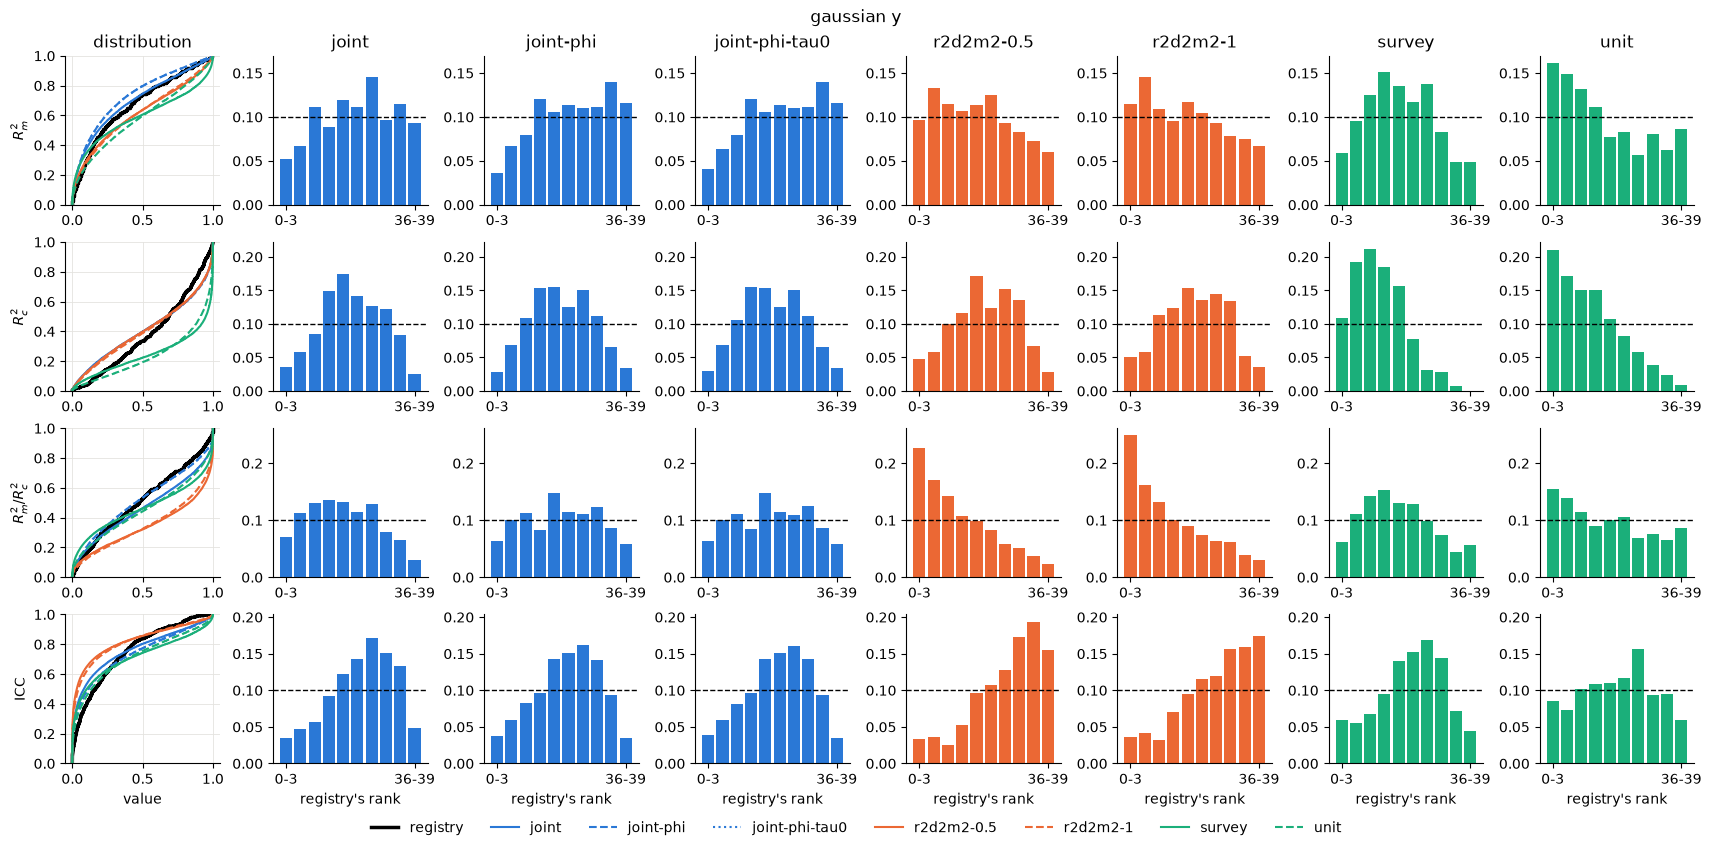

In [9]:
plotRanks('gaussian')

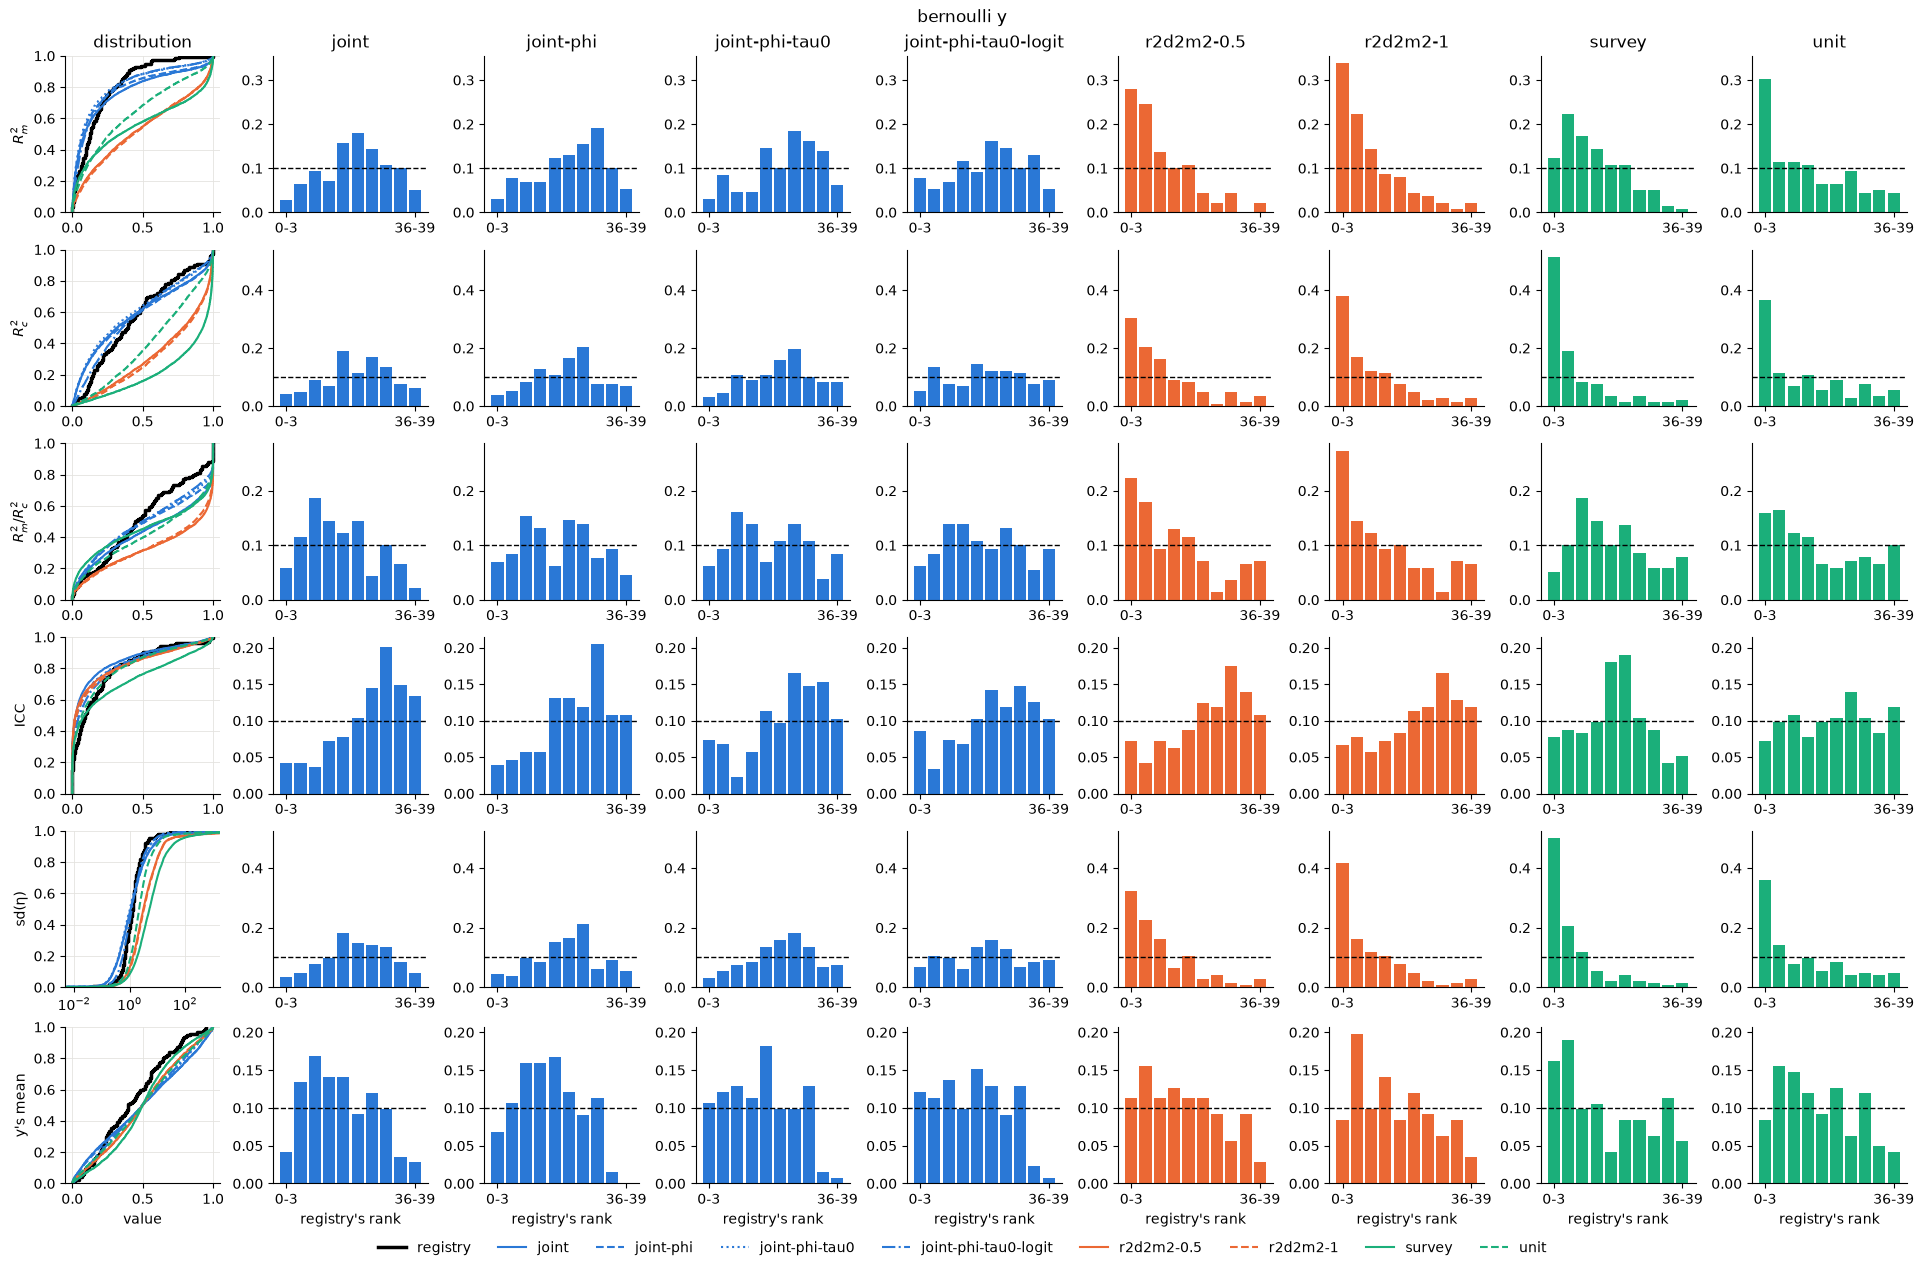

In [10]:
plotRanks('bernoulli')

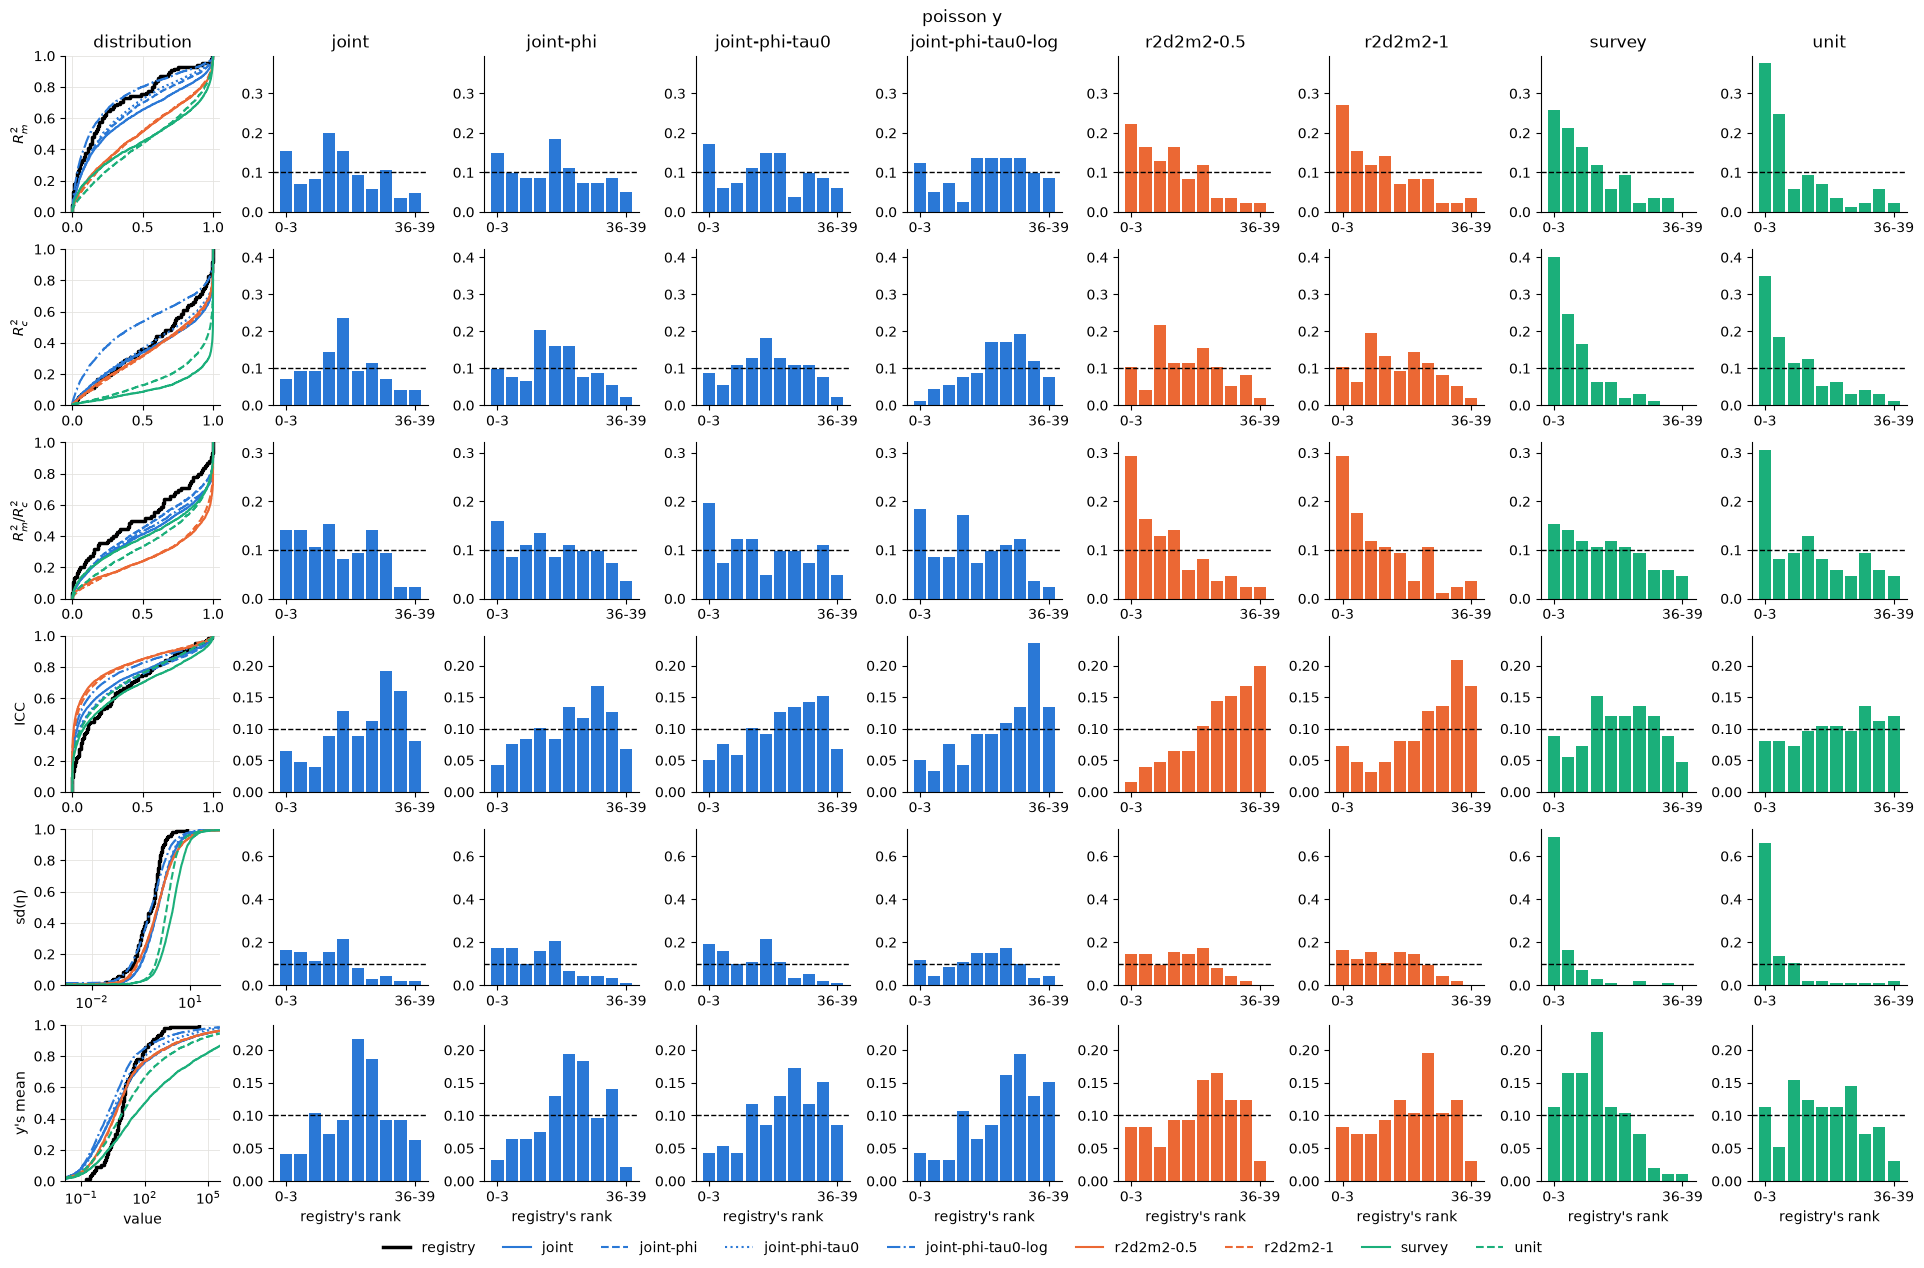

In [11]:
plotRanks('poisson')

## 7. Outside, containment and distance

Per family, measure and prior:
- **outside:** the share of registry fits outside the refits' range.
- **expected:** that share if the ranks are uniform.
- **vs joint:** the paired difference to the joint prior's share outside, with its 95 % interval.
- **distance:** the Wasserstein-1 distance between the registry and the refits.
- **refits in:** the share of refits inside the registry's band.
- **registry in:** the share of registry fits inside the refits' band.

In [12]:
def intervalClustered(difference: pd.Series) -> tuple[float, float]:
    # the mean's 95 % interval by the normal approximation, clustered by fit
    residuals = (difference - difference.mean()).groupby(level='task').sum()  # (fits,)
    clusters = len(residuals)
    variance = (residuals**2).sum() * clusters / (clusters - 1) / len(difference) ** 2
    half = 1.96 * math.sqrt(variance)
    return difference.mean() - half, difference.mean() + half


def compareArms(rng: np.random.Generator) -> pd.DataFrame:
    # a row per family, measure and prior
    outside = ranks.pivot_table(
        index=['family', 'measure', 'task', 'k'], columns='arm', values='outside'
    )
    rows = []
    for family in FAMILIES:
        for measure, label in MEASURES.items():
            in_registry = real[(real['family'] == family) & (real['measure'] == measure)]
            if in_registry.empty:
                continue
            ranked = ranks[(ranks['family'] == family) & (ranks['measure'] == measure)]
            units = outside.loc[(family, measure)]
            for arm in selectArms(family):
                under_arm = refits[
                    (refits['family'] == family)
                    & (refits['measure'] == measure)
                    & (refits['arm'] == arm)
                ]
                refit_values = under_arm['value'].to_numpy()[:, None]  # (s, 1)
                # the registry's fits the prior ran on, and the fits it shares with the joint prior
                on_fits = in_registry[in_registry['task'].isin(under_arm['task'])]
                registry_values = on_fits['value'].to_numpy()[:, None]  # (s, 1)
                difference = (units[arm] - units['joint']).dropna()
                [distance] = fidelity.distances(registry_values, refit_values, rng, permutations=0)
                low, high = math.nan, math.nan
                if arm != 'joint':
                    low, high = intervalClustered(difference)
                rows.append(
                    {
                        'family': family,
                        'measure': label,
                        'arm': arm,
                        'outside': units[arm].mean(),
                        'expected': ranked[ranked['arm'] == arm]['expected'].mean(),
                        'vs joint': difference.mean(),
                        'low': low,
                        'high': high,
                        'distance': distance.statistic,
                        'refits in': fidelity.containment(refit_values, registry_values).per_axis[
                            0
                        ],
                        'registry in': fidelity.containment(registry_values, refit_values).per_axis[
                            0
                        ],
                    }
                )
    return pd.DataFrame(rows).set_index(['family', 'measure', 'arm'])


comparison = compareArms(np.random.default_rng(SEED))
for family in FAMILIES:
    print(comparison.loc[family].round(3).to_string(), end='\n\n')

                                outside  expected  vs joint    low   high  distance  refits in  registry in
measure         arm                                                                                        
$R^2_m$         joint             0.035      0.05     0.000    NaN    NaN     0.037      0.979        0.980
                joint-phi         0.044      0.05     0.013 -0.002  0.027     0.066      0.983        0.972
                joint-phi-tau0    0.044      0.05     0.013 -0.002  0.027     0.066      0.983        0.972
                r2d2m2-0.5        0.043      0.05     0.009 -0.009  0.026     0.056      0.961        0.992
                r2d2m2-1          0.040      0.05     0.006 -0.012  0.023     0.054      0.968        0.990
                survey            0.029      0.05    -0.005 -0.022  0.011     0.081      0.908        0.992
                unit              0.089      0.05     0.054  0.030  0.078     0.078      0.962        0.990
$R^2_c$         joint       

In [13]:
# the measures the joint prior loses: it leaves more fits outside than uniform ranks would,
# and another prior leaves fewer, at no larger distance
joint_comparison = comparison.xs('joint', level='arm')
others = comparison.drop(index='joint', level='arm')
per_measure = others.index.droplevel('arm')
misses = joint_comparison['outside'] > joint_comparison['expected']
misses = misses.reindex(per_measure).to_numpy()
no_larger = others['distance'] <= joint_comparison['distance'].reindex(per_measure).to_numpy()
losses = others[misses & (others['high'] < 0) & no_larger]
if losses.empty:
    print('none')
else:
    print(losses[['outside', 'vs joint', 'high', 'distance']].round(3).to_string())

none


## 8. Singular fits and the slope over d

In [14]:
# the share of singular fits among the fits with estimates, in the registry and under each prior
fitted = records[records['fit_status'].isin(ESTIMATED)]
singular = (fitted['fit_status'] == 'singular').groupby([fitted['family'], fitted['arm']]).mean()
singular = singular.unstack()
singular.insert(0, 'registry', (tasks['status'] == 'singular').groupby(tasks['family']).mean())
print(singular.loc[FAMILIES].round(3).to_string())

arm        registry  joint  joint-phi  joint-phi-tau0  joint-phi-tau0-log  joint-phi-tau0-logit  r2d2m2-0.5  r2d2m2-1  survey   unit
family                                                                                                                              
gaussian      0.096  0.220      0.200           0.197                 NaN                   NaN       0.275     0.242   0.152  0.139
bernoulli     0.190  0.294      0.273           0.255                 NaN                 0.225       0.240     0.214   0.144  0.183
poisson       0.093  0.205      0.187           0.193                0.27                   NaN       0.266     0.234   0.086  0.127


In [15]:
def fitSlope(d: pd.Series, r2: pd.Series) -> dict[str, float]:
    # OLS of R²_m on log₂ d, its slope's 95 % interval by the normal approximation
    centered = np.log2(d) - np.log2(d).mean()
    slope = (centered * r2).sum() / (centered**2).sum()
    residuals = r2 - r2.mean() - slope * centered
    se = math.sqrt((residuals**2).sum() / (len(r2) - 2) / (centered**2).sum())
    return {'slope': slope, 'low': slope - 1.96 * se, 'high': slope + 1.96 * se, 'fits': len(r2)}


slopes = {}
for family in FAMILIES:
    in_registry = real[(real['family'] == family) & (real['measure'] == 'r2_marginal')]
    slopes[(family, 'registry')] = fitSlope(in_registry['rank'], in_registry['value'])
    under_arms = refits[(refits['family'] == family) & (refits['measure'] == 'r2_marginal')]
    for arm in selectArms(family):
        per_fit = under_arms[under_arms['arm'] == arm].groupby('task')[['rank', 'value']].mean()
        slopes[(family, arm)] = fitSlope(per_fit['rank'], per_fit['value'])
print(pd.DataFrame(slopes).T.round(3).to_string())

                                slope    low   high   fits
gaussian  registry              0.022  0.000  0.043  495.0
          joint                 0.027  0.022  0.032  495.0
          joint-phi             0.027  0.023  0.031  492.0
          joint-phi-tau0        0.027  0.023  0.031  492.0
          r2d2m2-0.5            0.088  0.082  0.095  495.0
          r2d2m2-1              0.088  0.081  0.094  495.0
          survey                0.082  0.072  0.091  495.0
          unit                  0.103  0.092  0.115  495.0
bernoulli registry              0.046  0.014  0.078  139.0
          joint                 0.032  0.015  0.048  139.0
          joint-phi             0.033  0.014  0.052  130.0
          joint-phi-tau0        0.028  0.010  0.046  130.0
          joint-phi-tau0-logit  0.028  0.010  0.045  130.0
          r2d2m2-0.5            0.116  0.094  0.138  139.0
          r2d2m2-1              0.124  0.103  0.146  139.0
          survey                0.115  0.095  0.135  139

## 9. Saturation

A link saturates when some |η| is so large that y is all but fixed at a row, as on a separated Bernoulli fit.<br>
lme4's max |η̂| reads it off a fit.<br>
MixedBench records it for each registry fit and `registry.py` for each refit, so the real y and the drawn ones are measured alike.

In [16]:
# the share of fits with some |η̂| above 10 on the logit and log links, the registry's and each prior's
LINKS = ['bernoulli', 'poisson']
saturated = (fitted['fit_max_abs_eta'] > 10).groupby([fitted['family'], fitted['arm']]).mean()
saturated = saturated.unstack()
per_fit = fits_table.drop_duplicates('task')
in_registry = (per_fit['max_abs_eta'] > 10).groupby(per_fit['family']).mean()
saturated.insert(0, 'registry', in_registry)
print(saturated.loc[LINKS].round(3).to_string())

arm        registry  joint  joint-phi  joint-phi-tau0  joint-phi-tau0-log  joint-phi-tau0-logit  r2d2m2-0.5  r2d2m2-1  survey   unit
family                                                                                                                              
bernoulli     0.148  0.233      0.229           0.190                 NaN                 0.186       0.513     0.532   0.637  0.393
poisson       0.041  0.233      0.219           0.182               0.127                   NaN       0.251     0.256   0.538  0.363


## 10. The joint prior split by its draws

Ranking a registry fit among only the joint refits whose draw falls in one bin ranks it under the joint prior restricted to that bin.<br>
So a bin previews a changed default without a rerun.
- **Tilt:** the mean normalized rank (r + V) / (m + 1) over the fits, its expectation over V and the tie-break.
- **0.5:** the restricted prior fits real tables.
- **Above 0.5:** the bin's refits run below the registry.
- **Interval:** ±1.96 standard errors, clustered by fit, for a bin of two fits or more.
- **Draws of the fit:** φ, Xβ's share of the predictor's variance, the intercept's location ν₀ and scale τ₀, and the predictor's sd τ, which split every measure.
- **τ on a Gaussian y:** set by the drawn R² and σ_ε, not drawn itself.
- **Draws of a factor:** its share of the predictor's variance, the spread of its σ_α scales (the sd of their logs) and its LKJ shape, which split only that factor's ICC.
- **Bins:** the joint draws' quartiles per family, a draw of 0 apart (φ without slopes, the spread of a lone or shared scale), and the LKJ shape by value, `none` for a factor without correlations.
- **m:** the mean number of refits per fit in the bin.
- **singular and saturated:** the shares of singular refits and of refits with some |η̂| above 10 in the bin, binned by the smallest value among a fit's factors for a factor's draw.

In [17]:
FIT_DRAWS = {
    'split_fixed': 'φ',
    'intercept_location': 'ν₀',
    'intercept_scale': 'τ₀',
    'predictor_sd': 'τ',
}
FACTOR_DRAWS = {
    'split': "factor's share",
    'sigma_alpha_spread': 'σ_α spread',
    'lkj_eta': 'LKJ shape',
}
ZERO_APART = ['split_fixed', 'sigma_alpha_spread']  # the draws that are 0 by construction
joint = records[records['arm'] == 'joint']

# a row per joint draw and factor of its fit
parts = []
for k in range(1, tasks['factors'].max() + 1):
    part = joint[['task', 'draw', 'family']].assign(k=k)
    for name in FACTOR_DRAWS:
        part[name] = joint[f'{name}_{k}']
    parts.append(part)
factor_draws = pd.concat(parts)
factor_draws = factor_draws[factor_draws['split'].notna()]  # NaN past the fit's factors

# a fit is singular or saturated as a whole, so it takes the smallest value among its factors
# (the lowest LKJ shape among its correlated factors, none without one)
smallest = factor_draws.groupby(['task', 'draw', 'family'], as_index=False)[
    list(FACTOR_DRAWS)
].min()


def binQuartiles(values: pd.Series, reference: pd.Series) -> pd.Series:
    # the reference draws' quartiles, labelled in order by their range
    edges = np.unique(reference.quantile([0, 0.25, 0.5, 0.75, 1]).to_numpy())
    labels = []
    for i in range(len(edges) - 1):
        labels.append(f'{i + 1}: {edges[i]:.2f} to {edges[i + 1]:.2f}')
    return pd.cut(values, edges, labels=labels, include_lowest=True).astype(object)


def binDraws(table: pd.DataFrame, name: str, reference: pd.DataFrame) -> pd.Series:
    # each row's bin of the draw `name`, per family at the reference draws' quartiles
    if name == 'lkj_eta':
        return table[name].map('{:.0f}'.format, na_action='ignore').fillna('none')
    bins = pd.Series(index=table.index, dtype=object)
    for family in FAMILIES:
        rows = table['family'] == family
        family_reference = reference[reference['family'] == family][name]
        if name in ZERO_APART:
            family_reference = family_reference[family_reference != 0]
        bins[rows] = binQuartiles(table[rows][name], family_reference)
    if name in ZERO_APART:
        bins[table[name] == 0] = '0: 0'
    return bins


def tiltPerBin(paired: pd.DataFrame) -> pd.DataFrame:
    # each fit's normalized rank among the bin's refits, then its mean over fits per family,
    # measure and bin, with the 95 % interval's half width
    units = paired.groupby(['family', 'measure', 'bin', 'task', 'k'], as_index=False).agg(
        below=('below', 'sum'), tied=('tied', 'sum'), m=('value', 'size')
    )
    units['rank'] = (units['below'] + units['tied'] / 2 + 0.5) / (units['m'] + 1)
    rows = []
    for (family, measure, bin), table in units.groupby(['family', 'measure', 'bin']):
        if table['task'].nunique() < 2:
            continue  # a bin of one fit has no interval clustered by fit
        low, high = intervalClustered(table.set_index('task')['rank'])
        tilt = {'tilt': table['rank'].mean(), 'half': (high - low) / 2, 'm': table['m'].mean()}
        rows.append({'family': family, 'measure': MEASURES[measure], 'bin': bin} | tilt)
    return pd.DataFrame(rows)


def showSplit(name: str) -> None:
    # the tilt per family and bin of one draw, with the bin's singular and saturated shares
    if name in FIT_DRAWS:
        bins = binDraws(joint, name, joint)
        draws = joint[['task', 'draw']].assign(bin=bins)
        paired = joint_paired.merge(draws, on=['task', 'draw'])
        fit_bins = draws
    else:
        bins = binDraws(factor_draws, name, factor_draws)
        draws = factor_draws[['task', 'draw', 'k']].assign(bin=bins)
        paired = joint_paired.merge(draws, on=['task', 'draw', 'k'])
        fit_bins = smallest[['task', 'draw']].assign(bin=binDraws(smallest, name, factor_draws))
    tilts = tiltPerBin(paired)
    tilts['cell'] = tilts['tilt'].map('{:.2f}'.format) + ' ±' + tilts['half'].map('{:.2f}'.format)
    table = tilts.pivot_table(
        index=['family', 'bin'], columns='measure', values='cell', aggfunc='first'
    )
    measures = []
    for label in MEASURES.values():
        if label in table.columns:
            measures.append(label)
    table = table[measures]
    table['m'] = tilts.groupby(['family', 'bin'])['m'].mean().round(1)

    # the singular and saturated shares among the bin's joint refits with estimates
    estimated = joint[joint['fit_status'].isin(ESTIMATED)].merge(fit_bins, on=['task', 'draw'])
    groups = [estimated['family'], estimated['bin']]
    table['singular'] = (estimated['fit_status'] == 'singular').groupby(groups).mean().round(3)
    on_links = estimated['family'].isin(LINKS)
    saturated = (estimated['fit_max_abs_eta'] > 10).where(on_links)
    table['saturated'] = saturated.groupby(groups).mean().round(3)
    print(f'{FIT_DRAWS.get(name) or FACTOR_DRAWS[name]}')
    print(table.loc[FAMILIES].to_string(), end='\n\n')


joint_paired = pairRegistry()
joint_paired = joint_paired[joint_paired['arm'] == 'joint']
registry_singular = (tasks['status'] == 'singular').groupby(tasks['family']).mean()
print(f'singular in the registry: {registry_singular.round(3).to_dict()}', end='\n\n')
for name in [*FIT_DRAWS, *FACTOR_DRAWS]:
    showSplit(name)

singular in the registry: {'bernoulli': 0.19, 'gaussian': 0.096, 'poisson': 0.093}



φ


measure                       $R^2_m$     $R^2_c$ $R^2_m / R^2_c$         ICC       sd(η)    y's mean     m  singular saturated
family    bin                                                                                                                  
gaussian  0: 0                    NaN  0.47 ±0.06             NaN  0.52 ±0.05         NaN         NaN  39.0     0.193       NaN
          1: 0.00 to 0.25  0.71 ±0.02  0.53 ±0.02      0.65 ±0.02  0.45 ±0.02         NaN         NaN   9.7     0.184       NaN
          2: 0.25 to 0.50  0.56 ±0.02  0.50 ±0.02      0.49 ±0.02  0.53 ±0.02         NaN         NaN   9.7     0.195       NaN
          3: 0.50 to 0.75  0.48 ±0.03  0.50 ±0.02      0.41 ±0.02  0.59 ±0.02         NaN         NaN   9.7     0.217       NaN
          4: 0.75 to 1.00  0.40 ±0.02  0.52 ±0.02      0.28 ±0.02  0.72 ±0.02         NaN         NaN   9.8     0.294       NaN
bernoulli 0: 0                    NaN  0.72 ±0.23             NaN  0.61 ±0.15  0.72 ±0.22  0.40 ±0.45  3

ν₀
measure                         $R^2_m$     $R^2_c$ $R^2_m / R^2_c$         ICC       sd(η)    y's mean     m  singular saturated
family    bin                                                                                                                    
gaussian  1: -3.00 to -1.48  0.54 ±0.02  0.51 ±0.02      0.46 ±0.02  0.57 ±0.02         NaN         NaN   9.7     0.220       NaN
          2: -1.48 to 0.00   0.54 ±0.02  0.51 ±0.02      0.46 ±0.02  0.56 ±0.02         NaN         NaN   9.8     0.221       NaN
          3: 0.00 to 1.50    0.54 ±0.02  0.51 ±0.02      0.46 ±0.02  0.57 ±0.02         NaN         NaN   9.8     0.218       NaN
          4: 1.50 to 3.00    0.52 ±0.02  0.50 ±0.02      0.44 ±0.02  0.57 ±0.02         NaN         NaN   9.8     0.222       NaN
bernoulli 1: -3.00 to -1.45  0.51 ±0.04  0.50 ±0.04      0.44 ±0.04  0.62 ±0.03  0.50 ±0.04  0.73 ±0.04   9.7     0.319     0.261
          2: -1.45 to -0.03  0.53 ±0.04  0.54 ±0.04      0.43 ±0.04  0.62 ±0.03  0.53 ±

τ
measure                       $R^2_m$     $R^2_c$ $R^2_m / R^2_c$         ICC       sd(η)    y's mean     m  singular saturated
family    bin                                                                                                                  
gaussian  1: 0.05 to 0.57  0.63 ±0.02  0.65 ±0.02      0.45 ±0.02  0.63 ±0.02         NaN         NaN   9.7     0.291       NaN
          2: 0.57 to 0.70  0.55 ±0.02  0.55 ±0.02      0.45 ±0.02  0.59 ±0.02         NaN         NaN   9.7     0.228       NaN
          3: 0.70 to 0.82  0.50 ±0.02  0.47 ±0.02      0.45 ±0.02  0.56 ±0.02         NaN         NaN   9.8     0.197       NaN
          4: 0.82 to 1.00  0.46 ±0.02  0.35 ±0.02      0.47 ±0.02  0.50 ±0.02         NaN         NaN   9.8     0.163       NaN
bernoulli 1: 0.25 to 0.51  0.73 ±0.04  0.76 ±0.03      0.41 ±0.04  0.73 ±0.03  0.77 ±0.03  0.45 ±0.04   9.6     0.430     0.129
          2: 0.51 to 1.01  0.62 ±0.04  0.66 ±0.04      0.43 ±0.04  0.67 ±0.04  0.66 ±0.04  0.45 ±0.04 

factor's share
measure                           ICC     m  singular saturated
family    bin                                                  
gaussian  1: 0.00 to 0.13  0.73 ±0.02  10.1     0.352       NaN
          2: 0.13 to 0.34  0.60 ±0.02  10.1     0.240       NaN
          3: 0.34 to 0.65  0.51 ±0.02  10.2     0.165       NaN
          4: 0.65 to 1.00  0.43 ±0.02  10.7     0.132       NaN
bernoulli 1: 0.00 to 0.11  0.73 ±0.03   9.8     0.445     0.274
          2: 0.11 to 0.31  0.65 ±0.04   9.8     0.297     0.241
          3: 0.31 to 0.60  0.57 ±0.04  10.0     0.257     0.238
          4: 0.60 to 1.00  0.51 ±0.04  10.5     0.195     0.189
poisson   1: 0.00 to 0.17  0.72 ±0.05   9.7     0.312     0.229
          2: 0.17 to 0.41  0.60 ±0.05   9.9     0.203     0.246
          3: 0.41 to 0.69  0.54 ±0.05   9.9     0.156     0.237
          4: 0.69 to 1.00  0.45 ±0.04  10.5     0.141     0.219



σ_α spread
measure                           ICC     m  singular saturated
family    bin                                                  
gaussian  0: 0             0.57 ±0.02  36.1     0.203       NaN
          1: 0.00 to 0.19  0.56 ±0.05   4.9     0.389       NaN
          2: 0.19 to 0.48  0.56 ±0.05   4.8     0.379       NaN
          3: 0.48 to 0.95  0.60 ±0.05   4.8     0.456       NaN
          4: 0.95 to 3.73  0.56 ±0.05   4.8     0.499       NaN
bernoulli 0: 0             0.62 ±0.03  36.4     0.297     0.231
          1: 0.00 to 0.23  0.63 ±0.11   5.2     0.333     0.235
          2: 0.23 to 0.56  0.59 ±0.08   5.0     0.193      0.25
          3: 0.56 to 1.08  0.61 ±0.09   5.1     0.229       0.3
          4: 1.08 to 2.62  0.55 ±0.11   5.1     0.213     0.311
poisson   0: 0             0.59 ±0.05  37.3     0.201     0.232
          1: 0.00 to 0.16  0.45 ±0.19   5.2     0.273     0.227
          2: 0.16 to 0.46  0.59 ±0.17   5.4     0.383     0.191
          3: 0.46 to 0.96  0.

## 11. Candidate defaults by reweighting

Section 10 restricts the joint prior to one bin of one draw.<br>
Importance sampling (IS) scores a whole candidate prior on the joint refits instead, without a rerun.<br>
Each joint draw is weighted by the candidate's density over the joint prior's at what it drew.<br>
Since the other draws do not depend on these, the weighted refits are the candidate's.

The candidates move the draws that section 10 ties to the lean.
- **φ:** Beta(1, 1) under the joint prior, the ICC's knob.
- **τ₀:** LogUniform(0.1, 10) under the joint prior, a knob of saturation.
- **τ:** LogUniform(0.25, 4) under the joint prior on the logit and log links, the stronger knob of saturation.
- **Unmoved draws:** weight 1, φ on a fit without slopes and τ on a Gaussian y.
- **Candidates:** φ pulled below 0.5, τ₀ and τ with a lower top, each alone and together.
- **Added after the first run:** φ ~ Beta(2, 3) with τ₀ to 3, the pair without τ, which the first seven left out.

In [18]:
# each candidate as its Glmm fields' overrides
CANDIDATES = {
    'joint': {},
    'φ Beta(1, 2)': {'fixed_share': Beta(1, 2)},
    'φ Beta(2, 3)': {'fixed_share': Beta(2, 3)},
    'τ₀ to 3': {'intercept_scale': LogUniform(0.1, 3)},
    'τ to 2': {'predictor_sd': LogUniform(0.25, 2)},
    'τ₀ to 3, τ to 2': {
        'intercept_scale': LogUniform(0.1, 3),
        'predictor_sd': LogUniform(0.25, 2),
    },
    'φ Beta(1, 2), τ₀ to 3, τ to 2': {
        'fixed_share': Beta(1, 2),
        'intercept_scale': LogUniform(0.1, 3),
        'predictor_sd': LogUniform(0.25, 2),
    },
    'φ Beta(2, 3), τ₀ to 3, τ to 2': {
        'fixed_share': Beta(2, 3),
        'intercept_scale': LogUniform(0.1, 3),
        'predictor_sd': LogUniform(0.25, 2),
    },
    'φ Beta(2, 3), τ₀ to 3': {'fixed_share': Beta(2, 3), 'intercept_scale': LogUniform(0.1, 3)},
}


def weighDraws(
    candidate: dict[str, Beta | LogUniform | Uniform | float],
    draws: pd.DataFrame,
    arm: str = 'joint',
) -> pd.Series:
    # each draw of one arm weighted by the candidate's density over the arm's at what the prior drew,
    # the arm's density its override of the field, else Glmm's default
    weights = pd.Series(1.0, index=draws.index)
    for field, distribution in candidate.items():
        drawn = readDraws(field, draws)
        own = OVERRIDES[arm].get(field, Glmm.model_fields[field].default)
        ratio = density(distribution, drawn) / density(own, drawn)
        weights = weights * ratio.fillna(1.0)
    return weights


def readDraws(field: str, draws: pd.DataFrame) -> pd.Series | pd.DataFrame:
    # each draw of a field, NaN where it moves nothing:
    # φ on a fit without slopes, τ on a Gaussian y, where it follows from R² and σ_ε,
    # and for the Dirichlet's concentration each factor's share among the factors
    match field:
        case 'fixed_share':
            return draws['split_fixed'].where(draws['split_fixed'] > 0)
        case 'intercept_location':
            return draws['intercept_location']
        case 'intercept_scale':
            return draws['intercept_scale']
        case 'predictor_sd':
            return draws['predictor_sd'].where(draws['family'] != 'gaussian')
        case 'split_alpha':
            columns = [f'split_{k}' for k in range(1, tasks['factors'].max() + 1)]
            splits = draws[columns]  # NaN past the fit's factors
            return splits.div(splits.sum(axis=1), axis=0)


def density(
    distribution: Beta | LogUniform | Uniform | float, values: pd.Series | pd.DataFrame
) -> pd.Series:
    # a field's distribution's density at the draws,
    # a concentration's the Dirichlet's over the factors' shares (1 for a lone factor)
    match distribution:
        case Beta(a=a, b=b):
            out = stats.beta(a, b).pdf(values)
        case LogUniform(low=low, high=high):
            out = stats.loguniform(low, high).pdf(values)
        case Uniform(low=low, high=high):
            out = stats.uniform(low, high - low).pdf(values)
        case float():
            factors = values.notna().sum(axis=1)
            normalizer = special.gammaln(distribution * factors) - factors * special.gammaln(
                distribution
            )
            out = np.exp(normalizer + special.xlogy(distribution - 1, values).sum(axis=1))
    return pd.Series(out, index=values.index)


weights = {}
for name, candidate in CANDIDATES.items():
    weights[name] = weighDraws(candidate, joint)

Per fit and factor, a candidate's weighted refits give four numbers.
- **F̂:** the weighted share of refits below the registry's estimate, ties halved.
- **ESS:** the Kish effective sample size (Σw)² / Σw², 39 under the joint prior.
- **Tilt:** (ESS · F̂ + 0.5) / (ESS + 1), section 10's tilt at weight 1.
- **Outside:** the chance that 39 new refits leave the registry outside their range, F³⁹ + (1 - F)³⁹, averaged over F ~ Beta(ESS · F̂ + 1, ESS · (1 - F̂) + 1).

The average matters, since F̂ rests on 39 refits at most.<br>
F̂³⁹ + (1 - F̂)³⁹ alone gives 7.8 % at uniform ranks, the average exactly 2/40 = 5 %, and it widens as the ESS falls.<br>
At weight 1 it differs from section 7's share outside fit by fit, so the joint prior is scored here by the same rule as each candidate.
- **outside:** the mean over the fits and factors.
- **vs joint:** the paired difference to the joint prior's, with its 95 % interval clustered by fit.

In [19]:
UNIT = [
    'family',
    'measure',
    'task',
    'k',
]  # a registry fit's factor, k = 0 for the fit's own measure


every_paired = pairRegistry()  # every prior's refits beside the registry's estimates


def scoreRegistry(draw_weights: pd.Series) -> pd.DataFrame:
    # per fit, measure and factor: the weighted share F̂ of one prior's refits below the registry,
    # the tilt and the chance to fall outside 39 new refits, the weights indexed by its records
    weighted = records.loc[draw_weights.index, ['task', 'draw', 'arm']].assign(weight=draw_weights)
    paired = every_paired.merge(weighted, on=['task', 'draw', 'arm'])
    paired['weight_below'] = paired['weight'] * (paired['below'] + paired['tied'] / 2)
    paired['weight_squared'] = paired['weight'] ** 2
    units = paired.groupby(UNIT, as_index=False).agg(
        weight=('weight', 'sum'), below=('weight_below', 'sum'), squared=('weight_squared', 'sum')
    )
    share = units['below'] / units['weight']  # F̂
    ess = units['weight'] ** 2 / units['squared']
    units['tilt'] = (ess * share + 0.5) / (ess + 1)
    units['outside'] = expectOutside(ess * share + 1, ess * (1 - share) + 1)
    return units


def expectOutside(a: pd.Series, b: pd.Series) -> pd.Series:
    # E[F^m + (1 - F)^m] for F ~ Beta(a, b), as E[F^m] = B(a + m, b) / B(a, b)
    log_normalizer = special.betaln(a, b)
    all_below = np.exp(special.betaln(a + REFITS, b) - log_normalizer)
    all_above = np.exp(special.betaln(a, b + REFITS) - log_normalizer)
    return all_below + all_above


def compareMeasures(scores: dict[str, pd.DataFrame]) -> pd.DataFrame:
    # a row per family, measure and candidate
    joint_outside = scores['joint'].set_index(UNIT)['outside']
    rows = []
    for family in FAMILIES:
        for measure, label in MEASURES.items():
            for name, scored in scores.items():
                part = scored[(scored['family'] == family) & (scored['measure'] == measure)]
                if part.empty:
                    continue
                part = part.set_index(UNIT)
                difference = part['outside'] - joint_outside.reindex(part.index)
                low, high = math.nan, math.nan
                if name != 'joint':
                    low, high = intervalClustered(difference)
                rows.append(
                    {
                        'family': family,
                        'measure': label,
                        'candidate': name,
                        'tilt': part['tilt'].mean(),
                        'outside': part['outside'].mean(),
                        'vs joint': difference.mean(),
                        'low': low,
                        'high': high,
                    }
                )
    return pd.DataFrame(rows).set_index(['family', 'measure', 'candidate'])


scores = {}
for name, draw_weights in weights.items():
    scores[name] = scoreRegistry(draw_weights)
measures = compareMeasures(scores)
for family in FAMILIES:
    print(measures.loc[family].round(3).to_string(), end='\n\n')

                                                tilt  outside  vs joint    low   high
measure         candidate                                                            
$R^2_m$         joint                          0.540    0.036     0.000    NaN    NaN
                φ Beta(1, 2)                   0.610    0.046     0.010  0.006  0.015
                φ Beta(2, 3)                   0.567    0.047     0.011  0.006  0.015
                τ₀ to 3                        0.541    0.037     0.001 -0.002  0.004
                τ to 2                         0.540    0.036     0.000  0.000  0.000
                τ₀ to 3, τ to 2                0.541    0.037     0.001 -0.002  0.004
                φ Beta(1, 2), τ₀ to 3, τ to 2  0.612    0.046     0.010  0.005  0.015
                φ Beta(2, 3), τ₀ to 3, τ to 2  0.568    0.048     0.012  0.006  0.017
                φ Beta(2, 3), τ₀ to 3          0.568    0.048     0.012  0.006  0.017
$R^2_c$         joint                          0.507  

Per fit, the weights also move the shares of section 5, 8 and 9.
- **failed:** the weighted share of the fit's draws without estimates.
- **singular:** the weighted share of its refits that lme4 flags as singular.
- **saturated:** the weighted share of its refits with some |η̂| above 10, on the logit and log links.
- **Each share:** the mean over fits, with the paired difference to the joint prior's and its 95 % interval.
- **ESS:** its smallest value and median over the fits, among the refits with estimates.

In [20]:
# per draw of any prior, whether it failed, turned singular or saturated, NaN where unrecorded
with_estimates = records['fit_status'].isin(ESTIMATED)
outcomes = {
    'failed': ~with_estimates,
    'singular': (records['fit_status'] == 'singular').where(with_estimates),
    'saturated': (records['fit_max_abs_eta'] > 10).where(
        with_estimates & records['family'].isin(LINKS)
    ),
}


def shareWeighted(outcome: pd.Series, draw_weights: pd.Series) -> pd.Series:
    # per fit, the weighted share of one prior's draws where the outcome holds,
    # among the draws that record it, the weights indexed by its records
    holds = outcome.loc[draw_weights.index]
    recorded = holds.notna()
    per_task = records.loc[draw_weights.index, 'task'][recorded]
    weighted = holds[recorded].astype(float) * draw_weights[recorded]
    return (
        weighted.groupby(per_task).sum() / draw_weights[recorded].groupby(per_task).sum()
    )  # (fits,)


def compareShares(weights: dict[str, pd.Series], base: str = 'joint') -> pd.DataFrame:
    # a row per candidate, each share paired with the base's
    families = tasks.set_index('task')['family']
    rows = {}
    for name, draw_weights in weights.items():
        row = {}
        for outcome, holds in outcomes.items():
            per_fit = shareWeighted(holds, draw_weights)
            in_base = shareWeighted(holds, weights[base])
            for family, share in per_fit.groupby(families):
                row[(family, outcome, 'share')] = share.mean()
                if outcome == 'failed':
                    continue
                difference = share - in_base.reindex(share.index)
                low, high = math.nan, math.nan
                if name != base:
                    low, high = intervalClustered(difference)
                row[(family, outcome, f'vs {base}')] = difference.mean()
                row[(family, outcome, 'low')] = low
                row[(family, outcome, 'high')] = high

        # the ESS per fit among the draws with estimates
        among = draw_weights[with_estimates.loc[draw_weights.index]]
        per_task = records.loc[among.index, 'task']
        ess = among.groupby(per_task).sum() ** 2 / (among**2).groupby(per_task).sum()
        for family, per_family in ess.groupby(families):
            row[(family, 'ESS', 'min')] = per_family.min()
            row[(family, 'ESS', 'median')] = per_family.median()
        rows[name] = row
    table = pd.DataFrame(rows).T
    table.index.name = 'candidate'
    return table


shares = compareShares(weights)
for family in FAMILIES:
    print(shares[family].dropna(axis=1, how='all').round(3).to_string(), end='\n\n')

                              failed singular                            ESS        
                               share    share vs joint    low   high     min  median
candidate                                                                           
joint                            0.0    0.220    0.000    NaN    NaN  39.000  39.000
φ Beta(1, 2)                     0.0    0.199   -0.021 -0.024 -0.018  23.645  29.572
φ Beta(2, 3)                     0.0    0.203   -0.017 -0.020 -0.014  22.380  28.923
τ₀ to 3                          0.0    0.221    0.001 -0.002  0.004  19.000  29.000
τ to 2                           0.0    0.220    0.000  0.000  0.000  39.000  39.000
τ₀ to 3, τ to 2                  0.0    0.221    0.001 -0.002  0.004  19.000  29.000
φ Beta(1, 2), τ₀ to 3, τ to 2    0.0    0.199   -0.021 -0.025 -0.017  13.409  22.295
φ Beta(2, 3), τ₀ to 3, τ to 2    0.0    0.202   -0.018 -0.022 -0.014  11.813  21.602
φ Beta(2, 3), τ₀ to 3            0.0    0.202   -0.018 -0.022 -0.

A candidate wins when three things hold.
- **ICC:** its tilt lies closer to 0.5 than the joint prior's on every family.
- **Fewer singular or saturated fits:** on some family, with the paired difference's 95 % interval below 0.
- **No new miss:** no measure the joint prior leaves at most 2/40 outside goes above it.
- **margin:** 2/40 minus the largest share outside among those measures.

In [21]:
def judgeCandidates(
    measures: pd.DataFrame, shares: pd.DataFrame, base: str = 'joint'
) -> pd.DataFrame:
    # a row per candidate: the families where its ICC tilt lies no closer to 0.5 than the base's,
    # the shares it cuts, the measures it newly misses, its margin and whether it wins,
    # the shares paired with the base's
    expected = 2 / (REFITS + 1)
    base_measures = measures.xs(base, level='candidate')
    base_icc = base_measures.xs('ICC', level='measure')['tilt']
    rows = []
    for name in measures.index.unique('candidate'):
        if name == base:
            continue
        own = measures.xs(name, level='candidate')
        own_icc = own.xs('ICC', level='measure')['tilt']
        not_closer = (own_icc - 0.5).abs() >= (base_icc - 0.5).abs()

        cuts = []
        for family in FAMILIES:
            for outcome in ['singular', 'saturated']:
                # NaN on a Gaussian y, which does not saturate
                high = shares.loc[name].get((family, outcome, 'high'), math.nan)
                if high < 0:
                    cuts.append(f'{outcome} {family}')

        covered = base_measures['outside'] <= expected
        new = covered & (own['outside'] > expected)
        margin = expected - own['outside'][covered].max()
        misses = []
        for family, measure in new[new].index:
            misses.append(f'{measure} {family}')

        wins = not not_closer.any() and len(cuts) > 0 and len(misses) == 0
        rows.append(
            {
                'candidate': name,
                'ICC not closer': ', '.join(not_closer[not_closer].index),
                'cuts': ', '.join(cuts),
                'new misses': ', '.join(misses),
                'margin': round(margin, 4),
                'wins': wins,
            }
        )
    return pd.DataFrame(rows).set_index('candidate')


print(judgeCandidates(measures, shares).to_string())

                                             ICC not closer                                                                                             cuts                       new misses  margin   wins
candidate                                                                                                                                                                                                   
φ Beta(1, 2)                                                                    singular gaussian, singular bernoulli, saturated bernoulli, singular poisson                                   0.0036   True
φ Beta(2, 3)                                                                                         singular gaussian, singular bernoulli, singular poisson                                   0.0032   True
τ₀ to 3                                             poisson                                       singular bernoulli, saturated bernoulli, saturated poisson                        

## 12. Candidate defaults as their own priors

### φ ~ Beta(2, 3) and τ₀ up to 3

Section 11 scores φ ~ Beta(2, 3) on the joint refits, at an ESS of 21 to 29 per fit.<br>
There it wins, closest to the bar on the Gaussian $R^2_m$.<br>
`joint-phi` checks that score with its own refits, from the joint prior with φ ~ Beta(2, 3) on the same random streams.<br>
It shares the joint prior's draws up to φ (ν₀, τ₀, r and τ), but not the draws after it.
- **Fits:** the 761 that `joint-phi` ran on (section 5), the joint prior restricted to them.
- **Bar:** every measure the joint prior leaves at most 2/40 outside stays there, by section 4's count.
- **Section 11's check:** its reweighted joint refits against `joint-phi`'s own, both scored by section 11's rule.
- **Option A:** `joint-phi-tau0`, run as its own prior, and predicted by reweighting the joint and `joint-phi` refits.


In [22]:
# the bar by section 4's count: the share of fits outside under the joint prior and each new prior,
# on the fits both ran on, and whether the new prior stays at most 2/40 where the joint prior is
EXPECTED = 2 / (REFITS + 1)
outside = ranks[ranks['task'].isin(fast)].pivot_table(
    index=['family', 'measure', 'task', 'k'], columns='arm', values='outside'
)
rows = []
for family in FAMILIES:
    for measure, label in MEASURES.items():
        if real[(real['family'] == family) & (real['measure'] == measure)].empty:
            continue
        units = outside.loc[(family, measure)]
        for arm in [ARM, ARM_TAU0]:
            difference = units[arm] - units['joint']
            low, high = intervalClustered(difference)
            row = {'joint': units['joint'].mean(), 'outside': units[arm].mean()}
            row |= {'vs joint': difference.mean(), 'low': low, 'high': high}
            rows.append({'family': family, 'measure': label, 'arm': arm} | row)
bar = pd.DataFrame(rows).set_index(['family', 'measure', 'arm'])
kept = bar['joint'] <= EXPECTED
bar['holds'] = ~kept | (bar['outside'] <= EXPECTED)
print(bar.round(3).to_string())
for arm in [ARM, ARM_TAU0]:
    under_arm = bar.xs(arm, level='arm')
    print(f"{arm}'s margin: {EXPECTED - under_arm['outside'][kept.xs(arm, level='arm')].max():.4f}")

                                          joint  outside  vs joint    low   high  holds
family    measure         arm                                                          
gaussian  $R^2_m$         joint-phi       0.031    0.044     0.013 -0.002  0.027   True
                          joint-phi-tau0  0.031    0.044     0.013 -0.002  0.027   True
          $R^2_c$         joint-phi       0.007    0.011     0.004 -0.003  0.012   True
                          joint-phi-tau0  0.007    0.011     0.004 -0.003  0.012   True
          $R^2_m / R^2_c$ joint-phi       0.017    0.022     0.005 -0.005  0.016   True
                          joint-phi-tau0  0.017    0.022     0.005 -0.005  0.016   True
          ICC             joint-phi       0.016    0.012    -0.004 -0.011  0.002   True
                          joint-phi-tau0  0.016    0.012    -0.004 -0.011  0.002   True
bernoulli $R^2_m$         joint-phi       0.008    0.015     0.008 -0.007  0.023   True
                          joint-

Section 11's rule scores six priors on the same 761 fits.
- **joint:** the joint prior at weight 1.
- **φ by IS:** the joint refits reweighted to φ ~ Beta(2, 3), section 11's prediction of `joint-phi`.
- **joint-phi:** its own refits at weight 1.
- **A by IS:** the joint refits reweighted to φ ~ Beta(2, 3) and τ₀ up to 3.
- **A from joint-phi:** `joint-phi`'s refits reweighted to τ₀ up to 3.
- **joint-phi-tau0:** option A's own refits at weight 1.


In [23]:
def keepTasks(draw_weights: pd.Series, on_tasks: pd.Index) -> pd.Series:
    # the weights of the draws on the given fits
    return draw_weights[records.loc[draw_weights.index, 'task'].isin(on_tasks)]


arm = records[records['arm'] == ARM]
checked = {
    'joint': keepTasks(weights['joint'], fast),
    'φ by IS': keepTasks(weights['φ Beta(2, 3)'], fast),
    ARM: pd.Series(1.0, index=arm.index),
    'A by IS': keepTasks(weights['φ Beta(2, 3), τ₀ to 3'], fast),
    f'A from {ARM}': weighDraws({'intercept_scale': LogUniform(0.1, 3)}, arm),
    ARM_TAU0: pd.Series(1.0, index=records[records['arm'] == ARM_TAU0].index),
}
checked_scores = {}
for name, draw_weights in checked.items():
    checked_scores[name] = scoreRegistry(draw_weights)
checked_measures = compareMeasures(checked_scores)
for family in FAMILIES:
    table = checked_measures.loc[family][['tilt', 'outside']].unstack('candidate')
    labels = []
    for label in MEASURES.values():
        if label in table.index:
            labels.append(label)
    table = table.loc[labels].reindex(columns=list(checked), level='candidate')
    print(family)
    print(table.round(3).to_string(), end='\n\n')

gaussian
                  tilt                                                           outside                                                          
candidate        joint φ by IS joint-phi A by IS A from joint-phi joint-phi-tau0   joint φ by IS joint-phi A by IS A from joint-phi joint-phi-tau0
measure                                                                                                                                           
$R^2_m$          0.542   0.570     0.570   0.570            0.568          0.570   0.034   0.045     0.040   0.047            0.040          0.040
$R^2_c$          0.509   0.505     0.501   0.502            0.499          0.501   0.012   0.014     0.014   0.015            0.015          0.014
$R^2_m / R^2_c$  0.453   0.496     0.497   0.499            0.499          0.498   0.021   0.026     0.025   0.028            0.025          0.025
ICC              0.575   0.537     0.536   0.535            0.535          0.536   0.016   0.016     0.013   

In [24]:
checked_shares = compareShares(checked)
for family in FAMILIES:
    print(checked_shares[family].dropna(axis=1, how='all').round(3).to_string(), end='\n\n')

                 failed singular                            ESS        
                  share    share vs joint    low   high     min  median
candidate                                                              
joint               0.0    0.219    0.000    NaN    NaN  39.000  39.000
φ by IS             0.0    0.202   -0.017 -0.020 -0.014  22.380  28.921
joint-phi           0.0    0.200   -0.020 -0.025 -0.014  39.000  39.000
A by IS             0.0    0.201   -0.018 -0.022 -0.014  11.813  21.605
A from joint-phi    0.0    0.202   -0.017 -0.023 -0.011  19.000  29.000
joint-phi-tau0      0.0    0.197   -0.022 -0.028 -0.016  39.000  39.000

                 failed singular                        saturated                            ESS        
                  share    share vs joint    low   high     share vs joint    low   high     min  median
candidate                                                                                               
joint             0.063    0.304    

In [25]:
print(judgeCandidates(checked_measures, checked_shares).to_string())

                 ICC not closer                                                                                             cuts new misses  margin  wins
candidate                                                                                                                                                
φ by IS                                                                  singular gaussian, singular bernoulli, singular poisson             0.0047  True
joint-phi                                                                singular gaussian, singular bernoulli, singular poisson             0.0102  True
A by IS                          singular gaussian, singular bernoulli, saturated bernoulli, singular poisson, saturated poisson             0.0031  True
A from joint-phi                 singular gaussian, singular bernoulli, saturated bernoulli, singular poisson, saturated poisson             0.0097  True
joint-phi-tau0                   singular gaussian, singular bernoulli, satu

### τ per link on top of A

Section 11 can lower τ's ceiling by reweighting, but not its floor, since no refit drew τ below 0.25.<br>
So each link's τ runs as its own prior on top of A (`joint-phi-tau0`), on the fast fits of its link.<br>
Each shares every draw with A but τ, which one uniform sets under either range.
- **`joint-phi-tau0-logit`:** τ ~ LogUniform(0.5, 3), where reweighting A's refits brings the logit link's tilts closest to 0.5.
- **`joint-phi-tau0-log`:** τ ~ LogUniform(0.1, 3), since 23 % of the real log-link fits have an sd(η̂) below 0.25.
- **The log link's ceiling:** 3, so that a ceiling of 2 is scored by reweighting its refits.
- **Bar:** section 4's count on the link's fast fits, against the joint prior and against A.
- **Regular fits:** the same count over the real fits with max |η̂| at most 10 and $R^2_c$ at least 0.02, since a refit matches a separated fit only by overfitting and a null one only by explaining nothing.

In [26]:
# the bar by section 4's count on each link's fast fits: the share of fits outside under
# the joint prior, A and the per-link prior, which stays at most 2/40 where either of them does,
# and the same count on the regular fits

# the regular real fits, neither separated (some |η̂| above 10) nor null (R²_c below 0.02)
real_fits = per_fit.set_index('task')[['max_abs_eta']]
real_fits['r2_conditional'] = real[real['measure'] == 'r2_conditional'].set_index('task')['value']
is_regular = (real_fits['max_abs_eta'] <= 10) & (real_fits['r2_conditional'] >= 0.02)
regular = real_fits[is_regular].index

rows = []
for family, arm in LINK_ARMS.items():
    on_link = tasks[tasks['task'].isin(fast) & (tasks['family'] == family)]['task']
    outside = ranks[ranks['task'].isin(on_link)].pivot_table(
        index=['measure', 'task', 'k'], columns='arm', values='outside'
    )
    for measure, label in MEASURES.items():
        if measure not in outside.index.unique('measure'):
            continue
        units = outside.loc[measure]
        regular_units = units[units.index.get_level_values('task').isin(regular)]
        row = {'family': family, 'measure': label}
        row |= {
            'joint': units['joint'].mean(),
            'A': units[ARM_TAU0].mean(),
            'outside': units[arm].mean(),
            'joint regular': regular_units['joint'].mean(),
            'A regular': regular_units[ARM_TAU0].mean(),
            'outside regular': regular_units[arm].mean(),
        }
        for base, name in [('joint', 'joint'), (ARM_TAU0, 'A')]:
            difference = units[arm] - units[base]
            low, high = intervalClustered(difference)
            row |= {f'vs {name}': difference.mean(), f'{name} low': low, f'{name} high': high}
        rows.append(row)
link_bar = pd.DataFrame(rows).set_index(['family', 'measure'])
below = link_bar['outside'] <= EXPECTED
link_bar['holds'] = below | ((link_bar['joint'] > EXPECTED) & (link_bar['A'] > EXPECTED))
print(link_bar.round(3).to_string())
for family, arm in LINK_ARMS.items():
    per_link = link_bar.loc[family]
    margins = []
    for name in ['joint', 'A']:
        margin = EXPECTED - per_link['outside'][per_link[name] <= EXPECTED].max()
        margins.append(f'{margin:.4f} against {name}')
    print(f"{arm}'s margin: {', '.join(margins)}")
    on_link = tasks[tasks['task'].isin(fast) & (tasks['family'] == family)]['task']
    print(f'{family}: {on_link.isin(regular).sum()} of {len(on_link)} fast fits regular')

                           joint      A  outside  joint regular  A regular  outside regular  vs joint  joint low  joint high   vs A  A low  A high  holds
family    measure                                                                                                                                        
bernoulli $R^2_m$          0.008  0.015    0.031          0.000      0.000            0.009     0.023     -0.003       0.049  0.015 -0.006   0.037   True
          $R^2_c$          0.015  0.030    0.061          0.000      0.000            0.000     0.045      0.010       0.081  0.030  0.001   0.060  False
          $R^2_m / R^2_c$  0.020  0.038    0.035          0.012      0.032            0.029     0.015     -0.001       0.031 -0.003 -0.011   0.005   True
          ICC              0.022  0.041    0.039          0.011      0.019            0.024     0.017     -0.006       0.040 -0.002 -0.019   0.015   True
          sd(η)            0.008  0.023    0.038          0.000      0.000  

The logit prior misses the bar on $R^2_c$ only by fits that are separated or null, as no prior leaves a regular fit outside there.<br>
The log prior misses it on y's mean, at 5.4 % outside, but never became a default.

Section 11's rule scores each link's priors on its fast fits, and candidates on top of them.
- **joint and A:** at weight 1.
- **τ by IS from A:** A's refits reweighted to the logit prior's τ, the prediction of its run.
- **The per-link prior:** at weight 1.
- **On top of it:** its refits reweighted to ν₀ up to 2 on the logit link or from -1.5 on the log link, to a Dirichlet among the factors at concentration 3 (`split_alpha`), and on the log link to τ up to 2.
- **A Gaussian y:** A's refits reweighted to `split_alpha` 3, since a default reaches every family.
- **ν₀:** Uniform(-3, 3) by default, the knob of y's mean on the logit and log links (section 10).
- **`split_alpha`:** 1 by default, a weight of 1 on a fit with one factor.

In [27]:
# per family, the candidates on top of its prior, which they reweight (A on a Gaussian y)
ON_TOP = {
    'gaussian': {'split_alpha 3': {'split_alpha': 3.0}},
    'bernoulli': {
        'ν₀ to 2': {'intercept_location': Uniform(-3, 2)},
        'split_alpha 3': {'split_alpha': 3.0},
        'ν₀ to 2, split_alpha 3': {'intercept_location': Uniform(-3, 2), 'split_alpha': 3.0},
    },
    'poisson': {
        'τ to 2': {'predictor_sd': LogUniform(0.1, 2)},
        'ν₀ from -1.5': {'intercept_location': Uniform(-1.5, 3)},
        'split_alpha 3': {'split_alpha': 3.0},
        'ν₀ from -1.5, split_alpha 3': {'intercept_location': Uniform(-1.5, 3), 'split_alpha': 3.0},
        'τ to 2, ν₀ from -1.5, split_alpha 3': {
            'predictor_sd': LogUniform(0.1, 2),
            'intercept_location': Uniform(-1.5, 3),
            'split_alpha': 3.0,
        },
    },
}
ON_TOP_OF = {
    'gaussian': ARM_TAU0,
    'bernoulli': LINK_ARMS['bernoulli'],
    'poisson': LINK_ARMS['poisson'],
}


def weighLink(family: str) -> dict[str, pd.Series]:
    # the weights of each prior and candidate on the family's fast fits
    on_link = tasks[tasks['task'].isin(fast) & (tasks['family'] == family)]['task']
    under_a = records[(records['arm'] == ARM_TAU0) & records['task'].isin(on_link)]
    link_weights = {
        'joint': keepTasks(weights['joint'], on_link),
        ARM_TAU0: pd.Series(1.0, index=under_a.index),
    }
    if family == 'bernoulli':
        tau = {'predictor_sd': LogUniform(0.5, 3)}
        link_weights['τ by IS from A'] = weighDraws(tau, under_a, ARM_TAU0)
    base = ON_TOP_OF[family]
    under_base = records[(records['arm'] == base) & records['task'].isin(on_link)]
    link_weights[base] = pd.Series(1.0, index=under_base.index)
    for name, candidate in ON_TOP[family].items():
        link_weights[name] = weighDraws(candidate, under_base, base)
    return link_weights


link_weights = {}
link_measures = {}
for family in FAMILIES:
    link_weights[family] = weighLink(family)
    link_scores = {}
    for name, draw_weights in link_weights[family].items():
        link_scores[name] = scoreRegistry(draw_weights)
    link_measures[family] = compareMeasures(link_scores)
    table = link_measures[family].loc[family][['tilt', 'outside']].unstack('candidate')
    labels = []
    for label in MEASURES.values():
        if label in table.index:
            labels.append(label)
    table = table.loc[labels].reindex(columns=list(link_weights[family]), level='candidate')
    print(family)
    print(table.round(3).to_string(), end='\n\n')

gaussian
                  tilt                              outside                             
candidate        joint joint-phi-tau0 split_alpha 3   joint joint-phi-tau0 split_alpha 3
measure                                                                                 
$R^2_m$          0.542          0.570         0.568   0.034          0.040         0.041
$R^2_c$          0.509          0.501         0.499   0.012          0.014         0.015
$R^2_m / R^2_c$  0.453          0.498         0.499   0.021          0.025         0.026
ICC              0.575          0.536         0.527   0.016          0.013         0.014



bernoulli
                  tilt                                                                                                 outside                                                                                                
candidate        joint joint-phi-tau0 τ by IS from A joint-phi-tau0-logit ν₀ to 2 split_alpha 3 ν₀ to 2, split_alpha 3   joint joint-phi-tau0 τ by IS from A joint-phi-tau0-logit ν₀ to 2 split_alpha 3 ν₀ to 2, split_alpha 3
measure                                                                                                                                                                                                                       
$R^2_m$          0.534          0.580          0.542                0.535   0.534         0.534                  0.534   0.016          0.019          0.027                0.029   0.031         0.027                  0.030
$R^2_c$          0.537          0.555          0.516                0.510   0.512         0.511   

poisson
                  tilt                                                                                                                                     outside                                                                                                                                    
candidate        joint joint-phi-tau0 joint-phi-tau0-log τ to 2 ν₀ from -1.5 split_alpha 3 ν₀ from -1.5, split_alpha 3 τ to 2, ν₀ from -1.5, split_alpha 3   joint joint-phi-tau0 joint-phi-tau0-log τ to 2 ν₀ from -1.5 split_alpha 3 ν₀ from -1.5, split_alpha 3 τ to 2, ν₀ from -1.5, split_alpha 3
measure                                                                                                                                                                                                                                                                                               
$R^2_m$          0.423          0.452              0.538  0.566        0.528         0.536                 

In [28]:
# the shares, each paired with the prior the candidates reweight
link_shares = {}
for family in FAMILIES:
    link_shares[family] = compareShares(link_weights[family], base=ON_TOP_OF[family])
    print(family)
    print(link_shares[family][family].dropna(axis=1, how='all').round(3).to_string(), end='\n\n')

gaussian
               failed singular                                     ESS       
                share    share vs joint-phi-tau0    low   high     min median
candidate                                                                    
joint             0.0    0.219             0.022  0.016  0.028  39.000   39.0
joint-phi-tau0    0.0    0.197             0.000    NaN    NaN  39.000   39.0
split_alpha 3     0.0    0.194            -0.004 -0.006 -0.002  10.412   39.0

bernoulli
                       failed singular                                       saturated                                           ESS       
                        share    share vs joint-phi-tau0-logit    low   high     share vs joint-phi-tau0-logit    low   high     min median
candidate                                                                                                                                  
joint                   0.063    0.304                   0.080  0.065  0.094     0.226      

In [29]:
# section 11's rule against the joint prior, and the candidates' against the prior they reweight
for family in FAMILIES:
    against_joint = judgeCandidates(link_measures[family], compareShares(link_weights[family]))
    base = ON_TOP_OF[family]
    on_top = judgeCandidates(link_measures[family], link_shares[family], base)
    print(f'{family}, against the joint prior')
    print(against_joint.to_string(), end='\n\n')
    print(f'{family}, against {base}')
    print(on_top.loc[list(ON_TOP[family])].to_string(), end='\n\n')

gaussian, against the joint prior
               ICC not closer               cuts new misses  margin  wins
candidate                                                                
joint-phi-tau0                 singular gaussian             0.0102  True
split_alpha 3                  singular gaussian             0.0092  True

gaussian, against joint-phi-tau0
              ICC not closer               cuts new misses  margin  wins
candidate                                                               
split_alpha 3                 singular gaussian             0.0092  True

bernoulli, against the joint prior
                       ICC not closer                                     cuts new misses  margin  wins
candidate                                                                                              
joint-phi-tau0                         singular bernoulli, saturated bernoulli             0.0197  True
τ by IS from A                         singular bernoulli, saturated 

poisson, against the joint prior
                                    ICC not closer                                 cuts        new misses  margin   wins
candidate                                                                                                               
joint-phi-tau0                                      singular poisson, saturated poisson                    0.0181   True
joint-phi-tau0-log                         poisson                    saturated poisson                    0.0009  False
τ to 2                                     poisson                    saturated poisson  y's mean poisson -0.0145  False
ν₀ from -1.5                               poisson                    saturated poisson  y's mean poisson -0.0042  False
split_alpha 3                              poisson                    saturated poisson                    0.0006  False
ν₀ from -1.5, split_alpha 3                poisson                    saturated poisson  y's mean poisson -0.0039  False

A's refits and the log prior's differ only in τ, so together they cover τ from 0.1 to 4.<br>
Each τ range between them is scored by weighting both by its density over the two priors' equal mixture (the balance heuristic of Veach & Guibas, 1995).
- **Shown:** the tilts and the singular and saturated shares, at a pooled ESS of about 65 per fit.
- **Left out:** the share outside, which an ESS above 39 narrows, so that it would not read like the other priors'.

In [30]:
# A's and the log prior's refits on the log link's fast fits, weighted to each τ range
# by its density over the equal mixture of the two priors' τ
POOLED_RANGES = [(0.25, 4), (0.2, 4), (0.15, 4), (0.1, 4), (0.15, 3), (0.1, 3)]
on_log = tasks[tasks['task'].isin(fast) & (tasks['family'] == 'poisson')]['task']
pooled = records[
    records['arm'].isin([ARM_TAU0, LINK_ARMS['poisson']]) & records['task'].isin(on_log)
]
tau = pooled['predictor_sd']
a_density = density(OVERRIDES[ARM_TAU0]['predictor_sd'], tau)
log_density = density(OVERRIDES[LINK_ARMS['poisson']]['predictor_sd'], tau)
mixture = 0.5 * a_density + 0.5 * log_density
pooled_weights = {'joint': keepTasks(weights['joint'], on_log)}
for low, high in POOLED_RANGES:
    pooled_weights[f'τ {low} to {high}'] = density(LogUniform(low, high), tau) / mixture

pooled_scores = {}
for name, draw_weights in pooled_weights.items():
    pooled_scores[name] = scoreRegistry(draw_weights)
tilts = compareMeasures(pooled_scores).loc['poisson']['tilt'].unstack('candidate')
labels = []
for label in MEASURES.values():
    if label in tilts.index:
        labels.append(label)
tilts = tilts.loc[labels, list(pooled_weights)]
pooled_shares = compareShares(pooled_weights)['poisson']
tilts.loc['singular'] = pooled_shares[('singular', 'share')]
tilts.loc['saturated'] = pooled_shares[('saturated', 'share')]
tilts.loc['ESS'] = pooled_shares[('ESS', 'median')]
print(tilts.round(3).to_string())

candidate         joint  τ 0.25 to 4  τ 0.2 to 4  τ 0.15 to 4  τ 0.1 to 4  τ 0.15 to 3  τ 0.1 to 3
measure                                                                                           
$R^2_m$           0.423        0.452       0.468        0.489       0.519        0.507       0.538
$R^2_c$           0.456        0.476       0.500        0.530       0.569        0.566       0.603
$R^2_m / R^2_c$   0.404        0.431       0.428        0.422       0.415        0.419       0.412
ICC               0.589        0.565       0.577        0.595       0.616        0.609       0.631
sd(η)             0.342        0.341       0.369        0.400       0.438        0.431       0.469
y's mean          0.549        0.579       0.587        0.597       0.611        0.623       0.635
singular          0.210        0.193       0.205        0.225       0.254        0.240       0.270
saturated         0.226        0.183       0.174        0.165       0.153        0.135       0.125
ESS       

## 13. Finding

### Only the joint prior is wider than real tables on the Gaussian and logit links

- **Joint:** at most 3.5 % of the registry fits outside its refits' range on a Gaussian y and 2.1 % on the logit link, where uniform ranks leave 5 %.
- **The log link:** 7.1 %, 7.9 % and 8.2 % outside on $R^2_m$, the fixed share and sd(η), where every prior misses all three.
- **Joint's band:** holds 95 % or more of the registry on every measure.
- **R2D2M2:** refits above the registry on the logit link's $R^2_m$, $R^2_c$ and sd(η), at more than three times the joint prior's distance.
- **Stated priors:** refits above the registry on $R^2_c$ and on the links' sd(η), with 18 % to 37 % of the logit and log fits outside.
- **Losses:** none, as the joint prior misses more fits than uniform ranks only on the log link, where no prior leaves significantly fewer.

### The joint prior leans toward the fixed effects on every link

- **ICC:** rising ranks on every family, so its grouping factors explain less than real ones.
- **Fixed share:** falling ranks on every family, most on the log link.
- **η on the log link:** falling sd(η) ranks, so η is wider than in real tables.
- **Singular fits:** more often than in the registry on every link, more than twice as often on a Gaussian y and on the log link.
- **Saturation:** some |η̂| above 10 in 23 % of the refits on either link, against 15 % of the real fits on the logit link and 4.1 % on the log link.
- **R2D2M2 and the stated priors:** saturate more often still.

### The joint prior split by its draws

- **φ:** the lean's knob, as the ICC's tilt rises with φ on every family while $R^2_m$'s and the fixed share's fall.
- **φ from 0.25 to 0.5:** tilts within 0.08 of 0.5 on every measure but the log link's sd(η).
- **A factor's share:** the smaller it is, the lower the factor's ICC and the more singular the fit.
- **Singular fits on a Gaussian y:** most often with a small factor share or correlated random effects, but no bin falls to the registry's share.
- **τ₀:** its top quartile doubles the saturated share on the logit and log links, and its refits explain more than real tables.
- **τ:** the level's knob on the logit and log links, its bottom quartile explaining less than real tables and its top quartile more, with some |η̂| above 10 in 44 % and 46 % of its refits.
- **ν₀:** a high ν₀ on the log link explains more than real tables, a low one turns singular more often.
- **y's mean:** ν₀ is its knob on the logit and log links, a low ν₀ drawing means below real ones and a high one above, while τ₀ barely moves it.
- **σ_α's spread and the LKJ shape:** no tilt on the ICC beyond the noise.

### Candidate defaults by reweighting

- **Winners:** φ ~ Beta(1, 2), φ ~ Beta(2, 3) and the pair of φ ~ Beta(2, 3) with τ₀ up to 3, their ICC tilts closer to 0.5 and their singular shares lower on every family.
- **Their cost:** the Gaussian $R^2_m$, whose refits explain less than real fits, at 4.6 % to 4.8 % outside.
- **φ ~ Beta(1, 2):** the ICC closest to 0.5, but $R^2_m$'s tilt at 0.61 on a Gaussian y and 0.60 on the logit link, where φ ~ Beta(2, 3) leaves 0.57 and 0.56.
- **τ₀ up to 3:** most failed draws gone on the logit link and half on the log link, and a fifth of the saturated refits, but no move on the ICC.
- **The pair:** both gains, with the Gaussian $R^2_m$ at 4.8 % outside, since τ₀'s weights widen the share outside there without moving $R^2_m$.
- **τ up to 2:** fewer saturated refits still, but refits that explain less than real tables on the logit link.
- **Singular fits on a Gaussian y:** above 19 % under every candidate, twice the registry's share.
- **y's mean:** a new miss on the log link only where τ up to 2 joins τ₀ up to 3.

### φ ~ Beta(2, 3) as its own prior

- **Bar:** held on the 761 fits it ran on, with at most 4.4 % outside on every measure the joint prior keeps within 2/40 (the Gaussian $R^2_m$).
- **Gaussian $R^2_m$:** 4.4 % outside, where the joint prior leaves 3.1 %, and section 11 predicted 4.5 % by its rule, where the run leaves 4.0 %.
- **ICC:** tilts of 0.54, 0.59 and 0.55, from the joint prior's 0.58, 0.63 and 0.59.
- **Singular fits:** 2.0 to 3.1 points fewer on every family.
- **Saturation:** no clear cut on either link.
- **The log link's sd(η):** 9.7 % of fits outside, from 8.6 %, each a real fit whose η is narrower than every refit's, on a measure the joint prior already misses.
- **Section 11's prediction:** every tilt and share outside within 0.015 of the run.
- **y's mean:** at most 2.2 % outside on either link.

### τ₀ up to 3 on top, as its own prior

- **Bar:** held, with at most 4.4 % outside on every measure the joint prior keeps within 2/40 (the Gaussian $R^2_m$).
- **Closest after it:** the logit link's ICC and fixed share at 4.1 % and 3.8 %, from the joint prior's 2.2 % and 2.0 %.
- **Failed draws:** 1.0 % and 3.9 % on the logit and log links, from 6.3 % and 7.5 %.
- **Saturation:** 19 % and 18 %, from 23 % on either link, against the real fits' 15 % and 4.1 %.
- **Singular fits:** 2.2, 4.9 and 1.6 points fewer than under the joint prior.
- **ICC:** tilts of 0.54, 0.59 and 0.56, within 0.01 of `joint-phi`'s.
- **The log link's sd(η):** 10.8 % outside, from `joint-phi`'s 9.7 %.
- **Reweighting `joint-phi`'s refits:** every share predicted within 1.1 points.
- **Reweighting the joint refits:** the Gaussian $R^2_m$ put at 4.7 % outside, where the run leaves 4.0 % by the same rule, since τ₀ leaves a Gaussian y's measures unmoved.

### τ per link on top of A, as its own prior

- **Logit link, bar:** missed by τ from 0.5 to 3 on $R^2_c$, with 6.1 % outside (8 of 132 fits), from A's 3.0 % and the joint prior's 1.5 %.
- **The count's noise:** 1.5 fits over the bar, where the count's sd is 2.5 fits.
- **The 8 fits:** each separated (an $R^2_c$ of 0.976 to 1.0) or null (0.001 to 0.02), and on the 110 regular fits no prior leaves one outside on $R^2_c$.
- **Its tilts:** 0.53, 0.51, 0.50 and 0.56 on $R^2_m$, $R^2_c$, sd(η) and the ICC, from A's 0.58, 0.56, 0.56 and 0.59.
- **Its singular fits:** 22.5 %, from A's 25.5 %, against the registry's 19 %.
- **Its saturation:** 18.6 %, from A's 19.0 %.
- **Its distance:** at most half A's on $R^2_c$ and sd(η).
- **Reweighting A's refits:** every tilt predicted within 0.02, the singular share within 0.6 points.
- **Log link, bar:** missed by τ from 0.1 to 3 on y's mean, with 5.4 % outside, from A's 3.2 %.
- **Its sd(η):** 5.4 % outside, from A's 10.8 %.
- **Its saturation:** 13 %, from A's 18 %.
- **Its cost:** refits that explain less than real tables, with tilts of 0.54, 0.61 and 0.63 on $R^2_m$, $R^2_c$ and the ICC, from A's 0.45, 0.47 and 0.56, and 27 % singular fits, from A's 19 %.
- **A ceiling of 2:** worse on each of these, and a new miss on y's mean.
- **The floors between 0.1 and 0.25:** sd(η)'s tilt and the ICC's rise together, so no range brings sd(η) to 0.5 with the other tilts near it.
- **`split_alpha` 3 on top:** a small gain on every family, the ICC 0.007 to 0.009 closer and 0.2 to 1.0 points fewer singular fits, at an ESS as low as 9.
- **ν₀ on top:** y's mean closer on the logit link (a tilt of 0.48, from 0.41) but the ICC no closer, and a new miss on the log link's y's mean.

### The slope over d

- **Registry:** $R^2_m$ barely climbs with d on a Gaussian y, but climbs on the logit and log links.
- **The joint prior and its variants:** inside the registry's interval on every link.
- **R2D2M2 and the stated priors:** climb faster than the registry's interval allows on a Gaussian y and on the logit link.

### Verdict

The joint prior stays, since no other prior takes a measure from it.<br>
It covers the levels of real grouped tables on the Gaussian and logit links, which [simulated.ipynb](simulated.ipynb) left open, and misses three of the log link's measures, as every prior does.<br>
But its grouping factors explain less than real ones, and its fits turn singular and saturate more often.<br>
φ ~ Beta(2, 3) and τ₀ up to 3 together fix part of that in their own run and hold the bar.<br>
φ brings the ICC closer and cuts singular fits, and τ₀ removes most failed draws and a fifth of the saturated refits.<br>
Both leave more of the log link's fits outside on sd(η) than the joint prior, 10.8 % from 8.6 %.<br>
On the logit link, τ from 0.5 to 3 on top brings the tilts of $R^2_m$, $R^2_c$, the fixed share and sd(η) to within 0.04 of 0.5 and singular fits closer to the registry's share.<br>
It leaves 8 of 132 fits outside on $R^2_c$, 1.5 fits over the bar, but each is separated or null, and no prior leaves a regular fit outside there.<br>
So the logit link keeps τ from 0.5 to 3 at the count's miss, since a training prior should not widen toward separated or null fits.<br>
On the log link, no range of τ fixes sd(η) without refits that explain less than real tables, so τ keeps its default there.<br>
So [the pair, with τ from 0.5 to 3 on the logit link, became the default](https://github.com/adkipnis/tabdgp/issues/79), at the log link's sd(η).

## References

Aguilar, J. E., & Bürkner, P.-C. (2023). Intuitive joint priors for Bayesian linear multilevel models: The R2D2M2 prior. *Electronic Journal of Statistics*, *17*(1), 1711-1767. https://doi.org/10.1214/23-EJS2136

Bates, D., Mächler, M., Bolker, B., & Walker, S. (2015). Fitting linear mixed-effects models using lme4. *Journal of Statistical Software*, *67*(1), 1-48. https://doi.org/10.18637/jss.v067.i01

Nakagawa, S., Johnson, P. C. D., & Schielzeth, H. (2017). The coefficient of determination R² and intra-class correlation coefficient from generalized linear mixed-effects models revisited and expanded. *Journal of the Royal Society Interface*, *14*(134), 20170213. https://doi.org/10.1098/rsif.2017.0213

Veach, E., & Guibas, L. J. (1995). Optimally combining sampling techniques for Monte Carlo rendering. In *Proceedings of the 22nd Annual Conference on Computer Graphics and Interactive Techniques* (pp. 419-428). https://doi.org/10.1145/218380.218498